In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Environment ready!")

Environment ready!


In [ ]:
# @title AI prompt cell

import ipywidgets as widgets
from IPython.display import display, HTML, Markdown,clear_output
from google.colab import ai

dropdown = widgets.Dropdown(
    options=[],
    layout={'width': 'auto'}
)

def update_model_list(new_options):
    dropdown.options = new_options
update_model_list(ai.list_models())

text_input = widgets.Textarea(
    placeholder='Ask me anything....',
    layout={'width': 'auto', 'height': '100px'},
)

button = widgets.Button(
    description='Submit Text',
    disabled=False,
    tooltip='Click to submit the text',
    icon='check'
)

output_area = widgets.Output(
     layout={'width': 'auto', 'max_height': '300px','overflow_y': 'scroll'}
)

def on_button_clicked(b):
    with output_area:
        output_area.clear_output(wait=False)
        accumulated_content = ""
        for new_chunk in ai.generate_text(prompt=text_input.value, model_name=dropdown.value, stream=True):
            if new_chunk is None:
                continue
            accumulated_content += new_chunk
            clear_output(wait=True)
            display(Markdown(accumulated_content))

button.on_click(on_button_clicked)
vbox = widgets.GridBox([dropdown, text_input, button, output_area])

display(HTML("""
<style>
.widget-dropdown select {
    font-size: 18px;
    font-family: "Arial", sans-serif;
}
.widget-textarea textarea {
    font-size: 18px;
    font-family: "Arial", sans-serif;
}
</style>
"""))
display(vbox)


GridBox(children=(Dropdown(layout=Layout(width='auto'), options=('google/gemini-2.5-flash', 'google/gemini-2.5…

In [ ]:
!wget -O etdd70.zip "https://zenodo.org/records/17513247/files/data.zip?download=1"

--2026-10-05 18:10:32--  https://zenodo.org/records/17513247/files/data.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.43.153, 188.185.48.75, 137.138.153.219, ...
Connecting to zenodo.org (zenodo.org)|188.185.43.153|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 133743551 (128M) [application/octet-stream]
Saving to: ‘etdd70.zip’

etdd70.zip          100%[===================>] 127.55M  3.46MB/s    in 58s     

2026-10-05 18:11:31 (2.19 MB/s) - ‘etdd70.zip’ saved [133743551/133743551]



In [ ]:
!rm -rf ETDD70
!mkdir -p ETDD70
!unzip -q -o etdd70.zip -d ETDD70

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
!find ETDD70 -maxdepth 3 -type f | head -30

ETDD70/data/Subject_1744_T1_Syllables_metrics.csv
ETDD70/data/Subject_1879_T4_Meaningful_Text_metrics.csv
ETDD70/data/Subject_1913_T5_Pseudo_Text_fixations.csv
ETDD70/data/Subject_1186_T1_Syllables_saccades.csv
ETDD70/data/Subject_1009_T5_Pseudo_Text_metrics.csv
ETDD70/data/Subject_1350_T4_Meaningful_Text_raw.csv
ETDD70/data/Subject_1380_T5_Pseudo_Text_raw.csv
ETDD70/data/Subject_1858_T4_Meaningful_Text_fixations.csv
ETDD70/data/Subject_1284_T4_Meaningful_Text_metrics.csv
ETDD70/data/Subject_1996_T5_Pseudo_Text_saccades.csv
ETDD70/data/Subject_1040_T4_Meaningful_Text_metrics.csv
ETDD70/data/Subject_1109_T5_Pseudo_Text_fixations.csv
ETDD70/data/Subject_1312_T4_Meaningful_Text_raw.csv
ETDD70/data/Subject_1082_T5_Pseudo_Text_saccades.csv
ETDD70/data/Subject_1284_T5_Pseudo_Text_metrics.csv
ETDD70/data/Subject_1038_T5_Pseudo_Text_fixations.csv
ETDD70/data/Subject_1003_T5_Pseudo_Text_metrics.csv
ETDD70/data/Subject_1186_T5_Pseudo_Text_saccades.csv
ETDD70/data/Subject_1166_T5_Pseudo_Text_metr

In [ ]:
import glob
import os

files = glob.glob("ETDD70/data/*.csv")

print("Total CSV files:", len(files))

print("\nFile types:")
for keyword in ["metrics", "fixations", "saccades", "raw"]:
    count = len([f for f in files if keyword in os.path.basename(f)])
    print(f"{keyword}: {count}")

Total CSV files: 840

File types:
metrics: 210
fixations: 210
saccades: 210
raw: 210


In [ ]:
metrics_files = glob.glob("ETDD70/data/*_metrics.csv")

print("Number of metrics files:", len(metrics_files))
print("\nFirst metrics file:")
print(metrics_files[0])

Number of metrics files: 210

First metrics file:
ETDD70/data/Subject_1744_T1_Syllables_metrics.csv


In [ ]:
sample_metrics = pd.read_csv(metrics_files[0])

print("Shape:", sample_metrics.shape)

print("\nColumns:")
print(sample_metrics.columns.tolist())

print("\nFirst 5 rows:")
display(sample_metrics.head())

Shape: (100, 35)

Columns:
['sid', 'stimfile', 'eye_used', 'trialid', 'n_fix_trial', 'sum_fix_dur_trial', 'dwell_time_trial', 'mean_fix_dur_trial', 'n_sacc_trial', 'sum_sacc_dur_trial', 'mean_sacc_dur_trial', 'mean_sacc_ampl_trial', 'ratio_progress_regress_trial', 'n_between_line_regress_trial', 'n_within_line_regress_trial', 'n_regress_trial', 'n_progress_trial', 'n_transit_trial', 'aoi', 'aoi_kind', 'content', 'dwell_time_aoi', 'n_fix_aoi', 'sum_fix_dur_aoi', 'mean_fix_dur_aoi', 'skipped_aoi', 'n_fix_first_visit_aoi', 'first_fix_dur_aoi', 'first_fix_land_pos_aoi', 'dwell_time_first_visit_aoi', 'sum_fix_dur_first_visit_aoi', 'sum_fix_dur_after_first_visit_aoi', 'dwell_time_rereading_aoi', 'n_revisits_aoi', 'task']

First 5 rows:


,sid,stimfile,eye_used,trialid,n_fix_trial,sum_fix_dur_trial,dwell_time_trial,mean_fix_dur_trial,n_sacc_trial,sum_sacc_dur_trial,...,skipped_aoi,n_fix_first_visit_aoi,first_fix_dur_aoi,first_fix_land_pos_aoi,dwell_time_first_visit_aoi,sum_fix_dur_first_visit_aoi,sum_fix_dur_after_first_visit_aoi,dwell_time_rereading_aoi,n_revisits_aoi,task
0,1744,s7_stimuli_t1.jpg,b,12,157,80484.382,85744.116,512.639376,156,5887.676,...,0,13,91.912,0.168324,5403.663,5115.669,0.000,0.000,0,T1_Syllables
1,1744,s7_stimuli_t1.jpg,b,12,157,80484.382,85744.116,512.639376,156,5887.676,...,0,1,460.014,0.571591,456.014,460.014,0.000,0.000,0,T1_Syllables
2,1744,s7_stimuli_t1.jpg,b,12,157,80484.382,85744.116,512.639376,156,5887.676,...,0,2,91.912,0.634318,227.997,203.995,524.094,516.091,2,T1_Syllables
3,1744,s7_stimuli_t1.jpg,b,12,157,80484.382,85744.116,512.639376,156,5887.676,...,0,1,399.724,0.671534,395.727,399.724,416.208,412.206,1,T1_Syllables
4,1744,s7_stimuli_t1.jpg,b,12,157,80484.382,85744.116,512.639376,156,5887.676,...,0,1,611.842,0.557614,607.846,611.842,0.000,0.000,0,T1_Syllables


In [ ]:
print("Number of features:", len(sample_metrics.columns))

for i, col in enumerate(sample_metrics.columns, 1):
    print(i, "->", col)

Number of features: 35
1 -> sid
2 -> stimfile
3 -> eye_used
4 -> trialid
5 -> n_fix_trial
6 -> sum_fix_dur_trial
7 -> dwell_time_trial
8 -> mean_fix_dur_trial
9 -> n_sacc_trial
10 -> sum_sacc_dur_trial
11 -> mean_sacc_dur_trial
12 -> mean_sacc_ampl_trial
13 -> ratio_progress_regress_trial
14 -> n_between_line_regress_trial
15 -> n_within_line_regress_trial
16 -> n_regress_trial
17 -> n_progress_trial
18 -> n_transit_trial
19 -> aoi
20 -> aoi_kind
21 -> content
22 -> dwell_time_aoi
23 -> n_fix_aoi
24 -> sum_fix_dur_aoi
25 -> mean_fix_dur_aoi
26 -> skipped_aoi
27 -> n_fix_first_visit_aoi
28 -> first_fix_dur_aoi
29 -> first_fix_land_pos_aoi
30 -> dwell_time_first_visit_aoi
31 -> sum_fix_dur_first_visit_aoi
32 -> sum_fix_dur_after_first_visit_aoi
33 -> dwell_time_rereading_aoi
34 -> n_revisits_aoi
35 -> task


In [ ]:
import re

task_counts = {
    "T1_Syllables": len(glob.glob("ETDD70/data/*_T1_Syllables_metrics.csv")),
    "T4_Meaningful_Text": len(glob.glob("ETDD70/data/*_T4_Meaningful_Text_metrics.csv")),
    "T5_Pseudo_Text": len(glob.glob("ETDD70/data/*_T5_Pseudo_Text_metrics.csv"))
}

print(task_counts)

{'T1_Syllables': 70, 'T4_Meaningful_Text': 70, 'T5_Pseudo_Text': 70}


In [ ]:
import re

task_counts = {
    "T1_Syllables": len(glob.glob("ETDD70/data/*_T1_Syllables_metrics.csv")),
    "T4_Meaningful_Text": len(glob.glob("ETDD70/data/*_T4_Meaningful_Text_metrics.csv")),
    "T5_Pseudo_Text": len(glob.glob("ETDD70/data/*_T5_Pseudo_Text_metrics.csv"))
}

print(task_counts)

{'T1_Syllables': 70, 'T4_Meaningful_Text': 70, 'T5_Pseudo_Text': 70}


In [ ]:
!wget -O dyslexia_class_label.csv \
"https://zenodo.org/records/17513247/files/dyslexia_class_label.csv?download=1"

--2026-10-05 18:29:39--  https://zenodo.org/records/17513247/files/dyslexia_class_label.csv?download=1
Resolving zenodo.org (zenodo.org)... 188.185.48.75, 188.184.98.114, 137.138.153.219, ...
Connecting to zenodo.org (zenodo.org)|188.185.48.75|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1357 (1.3K) [text/plain]
Saving to: ‘dyslexia_class_label.csv’

dyslexia_class_labe 100%[===================>]   1.33K  --.-KB/s    in 0.001s  

2026-10-05 18:29:40 (1.24 MB/s) - ‘dyslexia_class_label.csv’ saved [1357/1357]



In [ ]:
import pandas as pd

labels = pd.read_csv("dyslexia_class_label.csv")

print("Shape:", labels.shape)
print("\nColumns:")
print(labels.columns.tolist())

display(labels.head())

Shape: (70, 3)

Columns:
['subject_id', 'class_id', 'label']


,subject_id,class_id,label
0,1003,0,non-dyslexic
1,1016,0,non-dyslexic
2,1019,0,non-dyslexic
3,1033,0,non-dyslexic
4,1040,0,non-dyslexic


In [ ]:
print("\nClass distribution:")
print(labels.iloc[:, -1].value_counts())


Class distribution:
label
non-dyslexic    35
dyslexic        35
Name: count, dtype: int64


In [ ]:
print("Columns:")
print(labels.columns.tolist())

print("\nFirst 10 rows:")
display(labels.head(10))

Columns:


NameError: name 'labels' is not defined

In [ ]:
import pandas as pd

# Load the label file again
labels = pd.read_csv("dyslexia_class_label.csv")

# Display information
print("Shape:", labels.shape)

print("\nColumns:")
print(labels.columns.tolist())

print("\nFirst 10 rows:")
display(labels.head(10))

print("\nClass distribution:")
print(labels["label"].value_counts())

FileNotFoundError: [Errno 2] No such file or directory: 'dyslexia_class_label.csv'

In [ ]:
!wget -O dyslexia_class_label.csv \
"https://zenodo.org/records/17513247/files/dyslexia_class_label.csv?download=1"

--2026-10-06 03:32:57--  https://zenodo.org/records/17513247/files/dyslexia_class_label.csv?download=1
Resolving zenodo.org (zenodo.org)... 188.184.98.114, 188.185.48.75, 188.185.43.153, ...
Connecting to zenodo.org (zenodo.org)|188.184.98.114|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1357 (1.3K) [text/plain]
Saving to: ‘dyslexia_class_label.csv’

dyslexia_class_labe 100%[===================>]   1.33K  --.-KB/s    in 0.03s   

2026-10-06 03:32:58 (51.0 KB/s) - ‘dyslexia_class_label.csv’ saved [1357/1357]



In [ ]:
import pandas as pd

labels = pd.read_csv("dyslexia_class_label.csv")

print("Shape:", labels.shape)
print("\nColumns:")
print(labels.columns.tolist())

print("\nFirst 10 rows:")
display(labels.head(10))

print("\nClass distribution:")
print(labels.iloc[:, -1].value_counts())

Shape: (70, 3)

Columns:
['subject_id', 'class_id', 'label']

First 10 rows:


,subject_id,class_id,label
0,1003,0,non-dyslexic
1,1016,0,non-dyslexic
2,1019,0,non-dyslexic
3,1033,0,non-dyslexic
4,1040,0,non-dyslexic
5,1058,0,non-dyslexic
6,1065,0,non-dyslexic
7,1073,0,non-dyslexic
8,1075,0,non-dyslexic
9,1090,0,non-dyslexic



Class distribution:
label
non-dyslexic    35
dyslexic        35
Name: count, dtype: int64


In [ ]:
import glob
import os
import re
import pandas as pd

# Get all CSV files from ETDD70
all_files = glob.glob("ETDD70/data/*.csv")

records = []

for file in all_files:
    filename = os.path.basename(file)

    # Extract subject ID
    match = re.match(r"Subject_(\d+)_T(\d+)_(.+)\.csv", filename)

    if match:
        subject_id = int(match.group(1))
        task_id = "T" + match.group(2)
        data_type = match.group(3)

        records.append({
            "subject_id": subject_id,
            "task_id": task_id,
            "data_type": data_type,
            "file": file
        })

file_map = pd.DataFrame(records)

print("Total files mapped:", len(file_map))
display(file_map.head(10))

Total files mapped: 0


""


In [ ]:
file_map = file_map.merge(
    labels[["subject_id", "class_id", "label"]],
    on="subject_id",
    how="left"
)

print("Total files:", len(file_map))

print("\nMissing labels:")
print(file_map["label"].isna().sum())

print("\nLabel distribution:")
print(file_map["label"].value_counts())

display(file_map.head(10))

KeyError: 'subject_id'

In [ ]:
# ============================================================
# ETDD70 - MASTER DATASET SETUP
# ============================================================

import pandas as pd
import numpy as np
import glob
import os
import re

print("Starting ETDD70 dataset setup...\n")

# ------------------------------------------------------------
# 1. Load dyslexia labels
# ------------------------------------------------------------

labels = pd.read_csv("dyslexia_class_label.csv")

print("LABEL DATA")
print("----------")
print("Number of participants:", len(labels))
print("Columns:", labels.columns.tolist())

print("\nClass distribution:")
print(labels["label"].value_counts())


# ------------------------------------------------------------
# 2. Find all ETDD70 CSV files
# ------------------------------------------------------------

all_files = glob.glob("ETDD70/data/*.csv")

print("\n\nETDD70 FILES")
print("------------")
print("Total CSV files:", len(all_files))


# ------------------------------------------------------------
# 3. Extract information from filenames
# ------------------------------------------------------------

records = []

for file in all_files:

    filename = os.path.basename(file)

    # Example:
    # Subject_1744_T1_Syllables_metrics.csv

    match = re.match(
        r"Subject_(\d+)_T(\d+)_(.+)\.csv",
        filename
    )

    if match:

        subject_id = int(match.group(1))
        task_number = int(match.group(2))
        remaining = match.group(3)

        # Separate task name and data type
        # Example:
        # Syllables_metrics
        # Meaningful_Text_fixations

        task_name, data_type = remaining.rsplit("_", 1)

        records.append({
            "subject_id": subject_id,
            "task_number": task_number,
            "task_name": task_name,
            "data_type": data_type,
            "filename": filename,
            "file_path": file
        })


# ------------------------------------------------------------
# 4. Create file map
# ------------------------------------------------------------

file_map = pd.DataFrame(records)

print("\nFILE MAP")
print("--------")
print("Total mapped files:", len(file_map))

display(file_map.head(10))


# ------------------------------------------------------------
# 5. Attach dyslexia labels
# ------------------------------------------------------------

file_map = file_map.merge(
    labels[["subject_id", "class_id", "label"]],
    on="subject_id",
    how="left"
)


# ------------------------------------------------------------
# 6. Check whether every file has a label
# ------------------------------------------------------------

missing_labels = file_map["label"].isna().sum()

print("\nLABEL CONNECTION")
print("----------------")
print("Files without labels:", missing_labels)

print("\nLabel distribution:")
print(file_map["label"].value_counts(dropna=False))


# ------------------------------------------------------------
# 7. Check tasks
# ------------------------------------------------------------

print("\nTASK DISTRIBUTION")
print("-----------------")
print(file_map["task_name"].value_counts())


# ------------------------------------------------------------
# 8. Check data types
# ------------------------------------------------------------

print("\nDATA TYPE DISTRIBUTION")
print("----------------------")
print(file_map["data_type"].value_counts())


# ------------------------------------------------------------
# 9. Check participant coverage
# ------------------------------------------------------------

print("\nPARTICIPANT CHECK")
print("-----------------")
print(
    "Participants in label file:",
    labels["subject_id"].nunique()
)

print(
    "Participants in eye-tracking files:",
    file_map["subject_id"].nunique()
)


# ------------------------------------------------------------
# 10. Final success check
# ------------------------------------------------------------

if (
    missing_labels == 0
    and labels["subject_id"].nunique() == 70
    and file_map["subject_id"].nunique() == 70
):
    print("\n========================================")
    print("SUCCESS! ETDD70 DATASET IS READY.")
    print("========================================")
else:
    print("\nPlease check the values above.")

Starting ETDD70 dataset setup...

LABEL DATA
----------
Number of participants: 70
Columns: ['subject_id', 'class_id', 'label']

Class distribution:
label
non-dyslexic    35
dyslexic        35
Name: count, dtype: int64


ETDD70 FILES
------------
Total CSV files: 0

FILE MAP
--------
Total mapped files: 0


""


KeyError: 'subject_id'

In [ ]:
# ============================================================
# ETDD70 - RESTORE DATASET + BUILD FILE MAP
# ============================================================

import pandas as pd
import numpy as np
import glob
import os
import re

print("Checking ETDD70 dataset...\n")

# ------------------------------------------------------------
# STEP 1: Check whether the extracted dataset exists
# ------------------------------------------------------------

data_folder = "ETDD70/data"

if not os.path.exists(data_folder) or len(glob.glob(data_folder + "/*.csv")) == 0:

    print("ETDD70 eye-tracking files are not available.")
    print("Downloading the dataset again...\n")

    # Download the ETDD70 data
    !wget -q --show-progress -O etdd70.zip \
    "https://zenodo.org/records/17513247/files/data.zip?download=1"

    print("\nExtracting dataset...")

    !rm -rf ETDD70
    !mkdir -p ETDD70
    !unzip -q -o etdd70.zip -d ETDD70

    print("Dataset extracted successfully!\n")

else:
    print("ETDD70 eye-tracking files already exist.\n")


# ------------------------------------------------------------
# STEP 2: Find all CSV files
# ------------------------------------------------------------

all_files = glob.glob("ETDD70/data/*.csv")

print("Total ETDD70 CSV files:", len(all_files))


# ------------------------------------------------------------
# STEP 3: Create file map
# ------------------------------------------------------------

records = []

for file in all_files:

    filename = os.path.basename(file)

    match = re.match(
        r"Subject_(\d+)_T(\d+)_(.+)\.csv",
        filename
    )

    if match:

        subject_id = int(match.group(1))
        task_number = int(match.group(2))
        remaining = match.group(3)

        task_name, data_type = remaining.rsplit("_", 1)

        records.append({
            "subject_id": subject_id,
            "task_number": task_number,
            "task_name": task_name,
            "data_type": data_type,
            "filename": filename,
            "file_path": file
        })


file_map = pd.DataFrame(records)


# ------------------------------------------------------------
# STEP 4: Load labels
# ------------------------------------------------------------

labels = pd.read_csv("dyslexia_class_label.csv")


# ------------------------------------------------------------
# STEP 5: Connect labels
# ------------------------------------------------------------

file_map = file_map.merge(
    labels[["subject_id", "class_id", "label"]],
    on="subject_id",
    how="left"
)


# ------------------------------------------------------------
# STEP 6: Display results
# ------------------------------------------------------------

print("\n============================================")
print("ETDD70 DATASET STATUS")
print("============================================")

print("\nTotal CSV files:", len(all_files))
print("Total mapped files:", len(file_map))

print(
    "Unique participants:",
    file_map["subject_id"].nunique()
)

print(
    "Files without labels:",
    file_map["label"].isna().sum()
)

print("\nTask distribution:")
print(file_map["task_name"].value_counts())

print("\nData type distribution:")
print(file_map["data_type"].value_counts())

print("\nClass distribution:")
print(file_map["label"].value_counts())

print("\nFirst 10 mapped files:")
display(file_map.head(10))

print("\n============================================")
print("DATASET SETUP COMPLETE")
print("============================================")

Checking ETDD70 dataset...

ETDD70 eye-tracking files are not available.

etdd70.zip          100%[===================>] 127.55M  3.73MB/s    in 57s     

Extracting dataset...
Dataset extracted successfully!

Total ETDD70 CSV files: 840

ETDD70 DATASET STATUS

Total CSV files: 840
Total mapped files: 840
Unique participants: 70
Files without labels: 0

Task distribution:
task_name
Syllables          280
Meaningful_Text    280
Pseudo_Text        280
Name: count, dtype: int64

Data type distribution:
data_type
metrics      210
fixations    210
saccades     210
raw          210
Name: count, dtype: int64

Class distribution:
label
dyslexic        420
non-dyslexic    420
Name: count, dtype: int64

First 10 mapped files:


,subject_id,task_number,task_name,data_type,filename,file_path,class_id,label
0,1744,1,Syllables,metrics,Subject_1744_T1_Syllables_metrics.csv,ETDD70/data/Subject_1744_T1_Syllables_metrics.csv,1,dyslexic
1,1879,4,Meaningful_Text,metrics,Subject_1879_T4_Meaningful_Text_metrics.csv,ETDD70/data/Subject_1879_T4_Meaningful_Text_me...,1,dyslexic
2,1913,5,Pseudo_Text,fixations,Subject_1913_T5_Pseudo_Text_fixations.csv,ETDD70/data/Subject_1913_T5_Pseudo_Text_fixati...,1,dyslexic
3,1186,1,Syllables,saccades,Subject_1186_T1_Syllables_saccades.csv,ETDD70/data/Subject_1186_T1_Syllables_saccades...,0,non-dyslexic
4,1009,5,Pseudo_Text,metrics,Subject_1009_T5_Pseudo_Text_metrics.csv,ETDD70/data/Subject_1009_T5_Pseudo_Text_metric...,1,dyslexic
5,1350,4,Meaningful_Text,raw,Subject_1350_T4_Meaningful_Text_raw.csv,ETDD70/data/Subject_1350_T4_Meaningful_Text_ra...,1,dyslexic
6,1380,5,Pseudo_Text,raw,Subject_1380_T5_Pseudo_Text_raw.csv,ETDD70/data/Subject_1380_T5_Pseudo_Text_raw.csv,0,non-dyslexic
7,1858,4,Meaningful_Text,fixations,Subject_1858_T4_Meaningful_Text_fixations.csv,ETDD70/data/Subject_1858_T4_Meaningful_Text_fi...,1,dyslexic
8,1284,4,Meaningful_Text,metrics,Subject_1284_T4_Meaningful_Text_metrics.csv,ETDD70/data/Subject_1284_T4_Meaningful_Text_me...,0,non-dyslexic
9,1996,5,Pseudo_Text,saccades,Subject_1996_T5_Pseudo_Text_saccades.csv,ETDD70/data/Subject_1996_T5_Pseudo_Text_saccad...,1,dyslexic



DATASET SETUP COMPLETE


In [ ]:
# ============================================================
# STEP 2 — INSPECT ETDD70 METRICS
# ============================================================

# Select only metrics files
metrics_map = file_map[
    file_map["data_type"] == "metrics"
].copy()

print("Total metrics files:", len(metrics_map))

# ------------------------------------------------------------
# Load one metrics file
# ------------------------------------------------------------

sample_file = metrics_map.iloc[0]["file_path"]

print("\nSample file:")
print(sample_file)

sample_metrics = pd.read_csv(sample_file)

print("\nShape of sample metrics:")
print(sample_metrics.shape)

print("\nColumn names:")
print(sample_metrics.columns.tolist())

print("\nFirst 5 rows:")
display(sample_metrics.head())

print("\nData types:")
print(sample_metrics.dtypes)

print("\nMissing values:")
print(sample_metrics.isnull().sum())

Total metrics files: 210

Sample file:
ETDD70/data/Subject_1744_T1_Syllables_metrics.csv

Shape of sample metrics:
(100, 35)

Column names:
['sid', 'stimfile', 'eye_used', 'trialid', 'n_fix_trial', 'sum_fix_dur_trial', 'dwell_time_trial', 'mean_fix_dur_trial', 'n_sacc_trial', 'sum_sacc_dur_trial', 'mean_sacc_dur_trial', 'mean_sacc_ampl_trial', 'ratio_progress_regress_trial', 'n_between_line_regress_trial', 'n_within_line_regress_trial', 'n_regress_trial', 'n_progress_trial', 'n_transit_trial', 'aoi', 'aoi_kind', 'content', 'dwell_time_aoi', 'n_fix_aoi', 'sum_fix_dur_aoi', 'mean_fix_dur_aoi', 'skipped_aoi', 'n_fix_first_visit_aoi', 'first_fix_dur_aoi', 'first_fix_land_pos_aoi', 'dwell_time_first_visit_aoi', 'sum_fix_dur_first_visit_aoi', 'sum_fix_dur_after_first_visit_aoi', 'dwell_time_rereading_aoi', 'n_revisits_aoi', 'task']

First 5 rows:


,sid,stimfile,eye_used,trialid,n_fix_trial,sum_fix_dur_trial,dwell_time_trial,mean_fix_dur_trial,n_sacc_trial,sum_sacc_dur_trial,...,skipped_aoi,n_fix_first_visit_aoi,first_fix_dur_aoi,first_fix_land_pos_aoi,dwell_time_first_visit_aoi,sum_fix_dur_first_visit_aoi,sum_fix_dur_after_first_visit_aoi,dwell_time_rereading_aoi,n_revisits_aoi,task
0,1744,s7_stimuli_t1.jpg,b,12,157,80484.382,85744.116,512.639376,156,5887.676,...,0,13,91.912,0.168324,5403.663,5115.669,0.000,0.000,0,T1_Syllables
1,1744,s7_stimuli_t1.jpg,b,12,157,80484.382,85744.116,512.639376,156,5887.676,...,0,1,460.014,0.571591,456.014,460.014,0.000,0.000,0,T1_Syllables
2,1744,s7_stimuli_t1.jpg,b,12,157,80484.382,85744.116,512.639376,156,5887.676,...,0,2,91.912,0.634318,227.997,203.995,524.094,516.091,2,T1_Syllables
3,1744,s7_stimuli_t1.jpg,b,12,157,80484.382,85744.116,512.639376,156,5887.676,...,0,1,399.724,0.671534,395.727,399.724,416.208,412.206,1,T1_Syllables
4,1744,s7_stimuli_t1.jpg,b,12,157,80484.382,85744.116,512.639376,156,5887.676,...,0,1,611.842,0.557614,607.846,611.842,0.000,0.000,0,T1_Syllables



Data types:
sid                                    int64
stimfile                              object
eye_used                              object
trialid                                int64
n_fix_trial                            int64
sum_fix_dur_trial                    float64
dwell_time_trial                     float64
mean_fix_dur_trial                   float64
n_sacc_trial                           int64
sum_sacc_dur_trial                   float64
mean_sacc_dur_trial                  float64
mean_sacc_ampl_trial                 float64
ratio_progress_regress_trial         float64
n_between_line_regress_trial           int64
n_within_line_regress_trial            int64
n_regress_trial                        int64
n_progress_trial                       int64
n_transit_trial                        int64
aoi                                   object
aoi_kind                              object
content                               object
dwell_time_aoi                       float

In [ ]:
# ============================================================
# STEP 3 — CREATE PARTICIPANT-TASK MASTER DATASET
# ============================================================

print("Creating research-ready dataset...\n")

# ------------------------------------------------------------
# 1. Get only metrics files
# ------------------------------------------------------------

metrics_files = file_map[
    file_map["data_type"] == "metrics"
].copy()

print("Metrics files:", len(metrics_files))


# ------------------------------------------------------------
# 2. Define the eye-tracking feature groups
# ------------------------------------------------------------

trial_features = [
    "n_fix_trial",
    "sum_fix_dur_trial",
    "dwell_time_trial",
    "mean_fix_dur_trial",
    "n_sacc_trial",
    "sum_sacc_dur_trial",
    "mean_sacc_dur_trial",
    "mean_sacc_ampl_trial",
    "ratio_progress_regress_trial",
    "n_between_line_regress_trial",
    "n_within_line_regress_trial",
    "n_regress_trial",
    "n_progress_trial",
    "n_transit_trial"
]

aoi_features = [
    "dwell_time_aoi",
    "n_fix_aoi",
    "sum_fix_dur_aoi",
    "mean_fix_dur_aoi",
    "skipped_aoi",
    "n_fix_first_visit_aoi",
    "first_fix_dur_aoi",
    "first_fix_land_pos_aoi",
    "dwell_time_first_visit_aoi",
    "sum_fix_dur_first_visit_aoi",
    "sum_fix_dur_after_first_visit_aoi",
    "dwell_time_rereading_aoi",
    "n_revisits_aoi"
]


# ------------------------------------------------------------
# 3. Process every metrics file
# ------------------------------------------------------------

participant_task_data = []

for _, file_info in metrics_files.iterrows():

    # Read metrics file
    df = pd.read_csv(file_info["file_path"])

    subject_id = file_info["subject_id"]
    task_name = file_info["task_name"]
    task_number = file_info["task_number"]
    label = file_info["label"]
    class_id = file_info["class_id"]

    # --------------------------------------------------------
    # Trial-level data
    #
    # Trial features are repeated across AOIs.
    # Therefore take ONE row per trial.
    # --------------------------------------------------------

    trial_data = (
        df.groupby("trialid")[trial_features]
        .first()
        .reset_index()
    )

    # Average trial-level characteristics
    trial_summary = trial_data[trial_features].mean()


    # --------------------------------------------------------
    # AOI-level data
    # --------------------------------------------------------

    aoi_summary = df[aoi_features].mean()


    # --------------------------------------------------------
    # Combine features
    # --------------------------------------------------------

    row = {
        "subject_id": subject_id,
        "task_number": task_number,
        "task_name": task_name,
        "class_id": class_id,
        "label": label
    }

    # Add trial features
    for feature in trial_features:
        row[feature] = trial_summary[feature]

    # Add AOI features
    for feature in aoi_features:
        row[feature] = aoi_summary[feature]

    participant_task_data.append(row)


# ------------------------------------------------------------
# 4. Create final dataframe
# ------------------------------------------------------------

master_df = pd.DataFrame(participant_task_data)


# ------------------------------------------------------------
# 5. Sort neatly
# ------------------------------------------------------------

master_df = master_df.sort_values(
    ["subject_id", "task_number"]
).reset_index(drop=True)


# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("\n============================================")
print("MASTER DATASET CREATED")
print("============================================")

print("\nShape:", master_df.shape)

print(
    "\nUnique participants:",
    master_df["subject_id"].nunique()
)

print(
    "Unique participant-task rows:",
    len(master_df)
)

print("\nTasks:")
print(master_df["task_name"].value_counts())

print("\nClass distribution:")
print(master_df["label"].value_counts())

print("\nMissing values:")
print(master_df.isnull().sum().sum())

print("\nFirst 10 rows:")
display(master_df.head(10))

Creating research-ready dataset...

Metrics files: 210

MASTER DATASET CREATED

Shape: (210, 32)

Unique participants: 70
Unique participant-task rows: 210

Tasks:
task_name
Syllables          70
Meaningful_Text    70
Pseudo_Text        70
Name: count, dtype: int64

Class distribution:
label
non-dyslexic    105
dyslexic        105
Name: count, dtype: int64

Missing values:
0

First 10 rows:


,subject_id,task_number,task_name,class_id,label,n_fix_trial,sum_fix_dur_trial,dwell_time_trial,mean_fix_dur_trial,n_sacc_trial,...,mean_fix_dur_aoi,skipped_aoi,n_fix_first_visit_aoi,first_fix_dur_aoi,first_fix_land_pos_aoi,dwell_time_first_visit_aoi,sum_fix_dur_first_visit_aoi,sum_fix_dur_after_first_visit_aoi,dwell_time_rereading_aoi,n_revisits_aoi
0,1003,1,Syllables,0,non-dyslexic,136.0,67682.369,72973.586,497.664478,135.0,...,1104.268133,0.000000,2.390000,482.879640,0.367160,1260.655710,1211.381570,129.230630,128.270850,0.280000
1,1003,4,Meaningful_Text,0,non-dyslexic,141.0,57011.064,61314.610,404.333787,140.0,...,750.399606,0.112150,2.364486,357.876168,0.343293,990.077607,952.026093,93.343439,92.857579,0.186916
2,1003,5,Pseudo_Text,0,non-dyslexic,216.0,118053.580,125825.067,546.544352,215.0,...,1126.297222,0.045872,3.321101,614.693064,0.293232,1955.428312,1888.421606,203.871826,208.017945,0.302752
3,1009,1,Syllables,1,dyslexic,192.0,100766.879,107630.424,524.827495,191.0,...,1258.665412,0.000000,3.150000,566.093790,0.442732,1802.745770,1731.111370,276.625520,278.223460,0.520000
4,1009,4,Meaningful_Text,1,dyslexic,221.0,108950.353,115069.777,492.988023,220.0,...,924.327035,0.074766,3.803738,456.748748,0.418064,1945.479477,1873.595981,157.178393,159.233720,0.177570
5,1009,5,Pseudo_Text,1,dyslexic,238.0,153778.223,161845.768,646.126987,237.0,...,1448.378702,0.018349,3.899083,671.765257,0.443106,2701.928771,2619.692275,182.554367,183.692495,0.238532
6,1016,1,Syllables,0,non-dyslexic,166.0,98855.230,103938.848,595.513434,165.0,...,1379.038540,0.000000,2.900000,621.698400,0.464001,1779.840680,1727.406060,242.817680,248.097320,0.200000
7,1016,4,Meaningful_Text,0,non-dyslexic,204.0,108598.359,115105.800,532.344897,203.0,...,1010.687001,0.046729,3.588785,502.232159,0.356519,1966.407439,1894.748112,97.673794,98.421561,0.140187
8,1016,5,Pseudo_Text,0,non-dyslexic,286.0,181895.420,191394.977,635.997972,285.0,...,1361.355344,0.027523,4.366972,602.694954,0.364962,2883.345514,2778.579477,531.287183,544.718862,0.238532
9,1019,1,Syllables,0,non-dyslexic,158.0,54347.358,60130.722,343.970620,157.0,...,752.237645,0.000000,2.790000,336.332340,0.445892,1012.639740,954.482640,118.146420,120.187090,0.250000


In [ ]:
# ============================================================
# STEP 4A — STATISTICAL ANALYSIS
# Dyslexic vs Non-Dyslexic
# ============================================================

from scipy.stats import mannwhitneyu
import numpy as np
import pandas as pd

print("Starting statistical analysis...\n")


# ------------------------------------------------------------
# 1. Define feature columns
# ------------------------------------------------------------

id_columns = [
    "subject_id",
    "task_number",
    "task_name",
    "class_id",
    "label"
]

feature_columns = [
    col for col in master_df.columns
    if col not in id_columns
]


# ------------------------------------------------------------
# 2. Function for effect size
# ------------------------------------------------------------

def rank_biserial_effect(x, y):

    x = np.asarray(x)
    y = np.asarray(y)

    n1 = len(x)
    n2 = len(y)

    result = mannwhitneyu(
        x,
        y,
        alternative="two-sided"
    )

    U = result.statistic

    # Rank-biserial correlation
    effect = (2 * U) / (n1 * n2) - 1

    return result.pvalue, effect


# ------------------------------------------------------------
# 3. Perform statistical tests for every task
# ------------------------------------------------------------

statistical_results = []

tasks = master_df["task_name"].unique()

for task in tasks:

    task_data = master_df[
        master_df["task_name"] == task
    ]

    dyslexic = task_data[
        task_data["label"] == "dyslexic"
    ]

    non_dyslexic = task_data[
        task_data["label"] == "non-dyslexic"
    ]

    for feature in feature_columns:

        x = dyslexic[feature].dropna()
        y = non_dyslexic[feature].dropna()

        if len(x) > 0 and len(y) > 0:

            p_value, effect = rank_biserial_effect(
                x,
                y
            )

            statistical_results.append({

                "task": task,

                "feature": feature,

                "dyslexic_mean":
                    x.mean(),

                "non_dyslexic_mean":
                    y.mean(),

                "dyslexic_median":
                    x.median(),

                "non_dyslexic_median":
                    y.median(),

                "p_value":
                    p_value,

                "effect_size":
                    effect

            })


# ------------------------------------------------------------
# 4. Convert results into dataframe
# ------------------------------------------------------------

stats_df = pd.DataFrame(
    statistical_results
)


# ------------------------------------------------------------
# 5. Multiple-testing correction
# ------------------------------------------------------------

from statsmodels.stats.multitest import multipletests

stats_df["adjusted_p"] = np.nan

for task in stats_df["task"].unique():

    mask = stats_df["task"] == task

    corrected = multipletests(
        stats_df.loc[mask, "p_value"],
        method="fdr_bh"
    )

    stats_df.loc[mask, "adjusted_p"] = corrected[1]


# ------------------------------------------------------------
# 6. Significance column
# ------------------------------------------------------------

stats_df["significant"] = (
    stats_df["adjusted_p"] < 0.05
)


# ------------------------------------------------------------
# 7. Absolute effect size
# ------------------------------------------------------------

stats_df["abs_effect_size"] = (
    stats_df["effect_size"].abs()
)


# ------------------------------------------------------------
# 8. Sort results
# ------------------------------------------------------------

stats_df = stats_df.sort_values(
    ["task", "adjusted_p"]
).reset_index(drop=True)


# ------------------------------------------------------------
# 9. Display summary
# ------------------------------------------------------------

print("============================================")
print("STATISTICAL ANALYSIS COMPLETE")
print("============================================")

print("\nTotal statistical comparisons:",
      len(stats_df))

print("\nSignificant features by task:")

print(
    stats_df.groupby("task")["significant"]
    .sum()
)

print("\nTop features:")
display(
    stats_df.head(20)
)

Starting statistical analysis...

STATISTICAL ANALYSIS COMPLETE

Total statistical comparisons: 81

Significant features by task:
task
Meaningful_Text    25
Pseudo_Text        26
Syllables          25
Name: significant, dtype: int64

Top features:


,task,feature,dyslexic_mean,non_dyslexic_mean,dyslexic_median,non_dyslexic_median,p_value,effect_size,adjusted_p,significant,abs_effect_size
0,Meaningful_Text,n_fix_trial,276.257143,179.857143,254.000000,171.000000,1.247588e-09,0.844898,4.365990e-09,True,0.844898
1,Meaningful_Text,sum_fix_dur_trial,141971.160629,64419.052600,124369.439000,61514.451000,1.455330e-09,0.841633,4.365990e-09,True,0.841633
2,Meaningful_Text,dwell_time_trial,151835.385829,70398.175914,132872.318000,67301.993000,1.168731e-09,0.846531,4.365990e-09,True,0.846531
3,Meaningful_Text,n_sacc_trial,275.257143,178.857143,253.000000,170.000000,1.247588e-09,0.844898,4.365990e-09,True,0.844898
4,Meaningful_Text,dwell_time_aoi,2755.935749,1252.638864,2408.313972,1198.660888,1.168731e-09,0.846531,4.365990e-09,True,0.846531
5,Meaningful_Text,n_fix_aoi,5.103872,3.307877,4.691589,3.121495,1.246762e-09,0.844898,4.365990e-09,True,0.844898
6,Meaningful_Text,sum_fix_dur_aoi,5264.839762,2376.825237,4588.908000,2259.694168,1.352917e-09,0.843265,4.365990e-09,True,0.843265
7,Meaningful_Text,sum_fix_dur_after_first_visit_aoi,437.541961,117.782821,327.260150,101.937065,3.833340e-10,0.871020,4.365990e-09,True,0.871020
8,Meaningful_Text,dwell_time_rereading_aoi,450.063031,120.632260,332.643252,103.614318,4.455436e-10,0.867755,4.365990e-09,True,0.867755
9,Meaningful_Text,n_transit_trial,144.200000,114.657143,139.000000,112.000000,2.823410e-09,0.826122,7.623207e-09,True,0.826122


In [ ]:
# ============================================================
# STEP 4B — CROSS-TASK FEATURE STABILITY
# ============================================================

print("Finding features that are significant across all tasks...\n")

# ------------------------------------------------------------
# 1. Keep statistically significant features
# ------------------------------------------------------------

significant_features = stats_df[
    stats_df["significant"] == True
].copy()


# ------------------------------------------------------------
# 2. Count how many tasks each feature is significant in
# ------------------------------------------------------------

feature_stability = (
    significant_features
    .groupby("feature")["task"]
    .nunique()
    .reset_index()
)

feature_stability.columns = [
    "feature",
    "number_of_tasks"
]


# ------------------------------------------------------------
# 3. Add task names
# ------------------------------------------------------------

task_presence = (
    significant_features
    .groupby("feature")["task"]
    .apply(lambda x: ", ".join(sorted(x)))
    .reset_index()
)

task_presence.columns = [
    "feature",
    "significant_tasks"
]


# ------------------------------------------------------------
# 4. Combine
# ------------------------------------------------------------

feature_stability = feature_stability.merge(
    task_presence,
    on="feature"
)


# ------------------------------------------------------------
# 5. Sort by stability
# ------------------------------------------------------------

feature_stability = feature_stability.sort_values(
    ["number_of_tasks", "feature"],
    ascending=[False, True]
).reset_index(drop=True)


# ------------------------------------------------------------
# 6. Add stability category
# ------------------------------------------------------------

def classify_stability(n):

    if n == 3:
        return "STABLE_ACROSS_ALL_TASKS"

    elif n == 2:
        return "PARTIALLY_STABLE"

    else:
        return "TASK_SPECIFIC"


feature_stability["stability"] = (
    feature_stability["number_of_tasks"]
    .apply(classify_stability)
)


# ------------------------------------------------------------
# 7. Display results
# ------------------------------------------------------------

print("============================================")
print("CROSS-TASK STABILITY RESULTS")
print("============================================")

print("\nNumber of stable features:")
print(
    (feature_stability["number_of_tasks"] == 3).sum()
)

print("\nNumber of partially stable features:")
print(
    (feature_stability["number_of_tasks"] == 2).sum()
)

print("\nNumber of task-specific features:")
print(
    (feature_stability["number_of_tasks"] == 1).sum()
)

print("\nFeature stability table:")
display(feature_stability)

Finding features that are significant across all tasks...

CROSS-TASK STABILITY RESULTS

Number of stable features:
24

Number of partially stable features:
2

Number of task-specific features:
0

Feature stability table:


,feature,number_of_tasks,significant_tasks,stability
0,dwell_time_aoi,3,"Meaningful_Text, Pseudo_Text, Syllables",STABLE_ACROSS_ALL_TASKS
1,dwell_time_first_visit_aoi,3,"Meaningful_Text, Pseudo_Text, Syllables",STABLE_ACROSS_ALL_TASKS
2,dwell_time_rereading_aoi,3,"Meaningful_Text, Pseudo_Text, Syllables",STABLE_ACROSS_ALL_TASKS
3,dwell_time_trial,3,"Meaningful_Text, Pseudo_Text, Syllables",STABLE_ACROSS_ALL_TASKS
4,first_fix_dur_aoi,3,"Meaningful_Text, Pseudo_Text, Syllables",STABLE_ACROSS_ALL_TASKS
5,first_fix_land_pos_aoi,3,"Meaningful_Text, Pseudo_Text, Syllables",STABLE_ACROSS_ALL_TASKS
6,mean_fix_dur_aoi,3,"Meaningful_Text, Pseudo_Text, Syllables",STABLE_ACROSS_ALL_TASKS
7,mean_fix_dur_trial,3,"Meaningful_Text, Pseudo_Text, Syllables",STABLE_ACROSS_ALL_TASKS
8,mean_sacc_ampl_trial,3,"Meaningful_Text, Pseudo_Text, Syllables",STABLE_ACROSS_ALL_TASKS
9,n_fix_aoi,3,"Meaningful_Text, Pseudo_Text, Syllables",STABLE_ACROSS_ALL_TASKS


Starting correlation analysis...
Number of stable features: 24

Correlation matrix created.
Matrix shape: (24, 24)


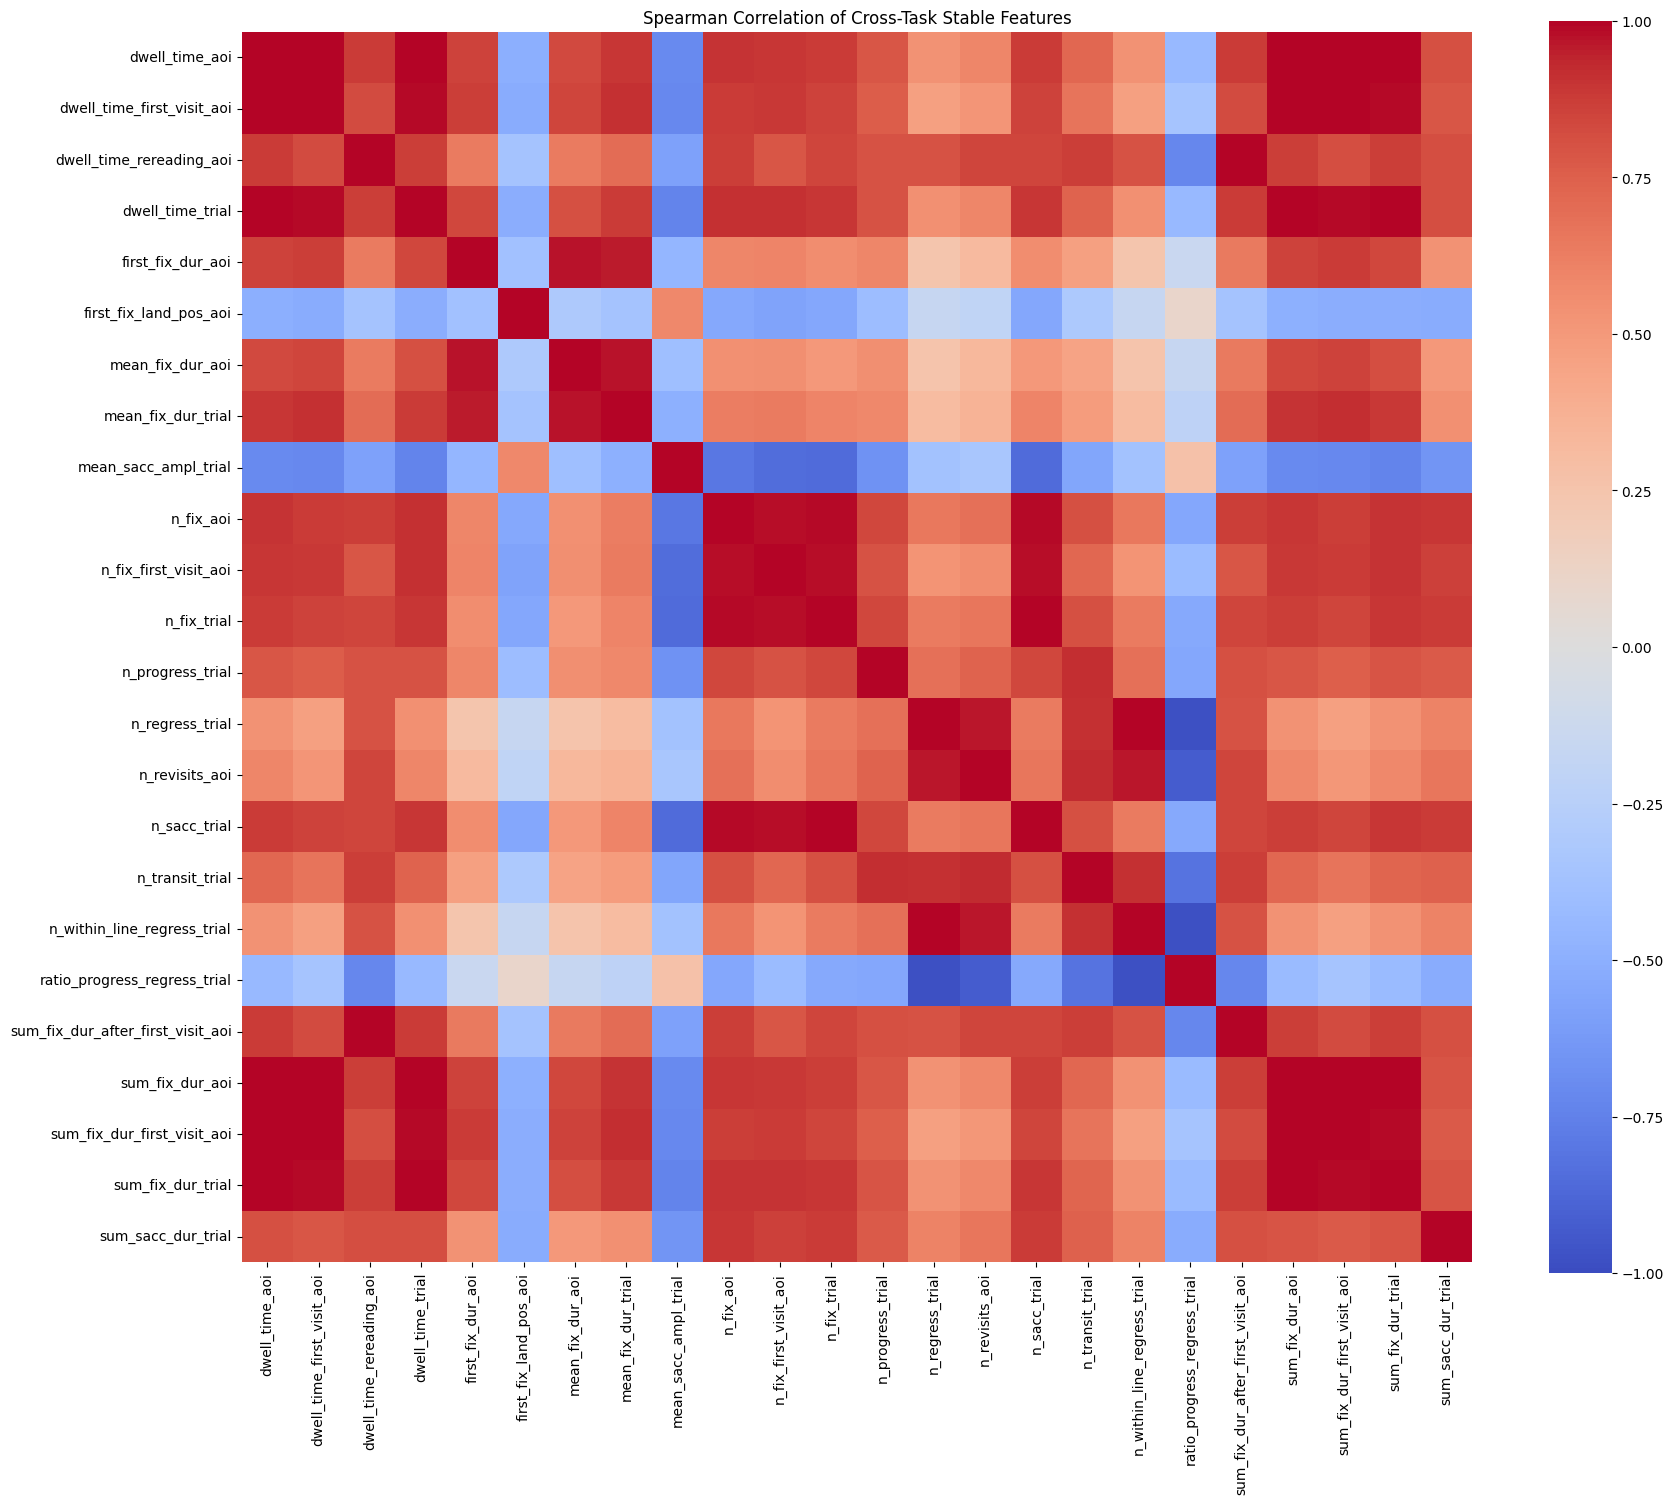

In [ ]:
# ============================================
# STEP 4C: CORRELATION ANALYSIS
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Starting correlation analysis...")

# Get features stable across all 3 tasks
stable_features = (
    feature_stability[
        feature_stability["stability"] == "STABLE_ACROSS_ALL_TASKS"
    ]["feature"]
    .tolist()
)

print(f"Number of stable features: {len(stable_features)}")

# Create correlation matrix
corr_matrix = master_df[stable_features].corr(method="spearman")

# Display correlation matrix
print("\nCorrelation matrix created.")
print("Matrix shape:", corr_matrix.shape)

# Plot heatmap
plt.figure(figsize=(18, 15))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Spearman Correlation of Cross-Task Stable Features")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# STEP 4D: NON-REDUNDANT STABLE FEATURE SELECTION
# ============================================

# Rank stable features by their average effect size across all tasks
stable_summary = (
    stats_df[stats_df["feature"].isin(stable_features)]
    .groupby("feature")
    .agg(
        mean_abs_effect=("abs_effect_size", "mean"),
        min_abs_effect=("abs_effect_size", "min"),
        max_abs_effect=("abs_effect_size", "max")
    )
    .sort_values("mean_abs_effect", ascending=False)
)

print("Stable features ranked by average effect size:")
display(stable_summary)

# Absolute correlation matrix
abs_corr = corr_matrix.abs()

# Greedy selection:
# Keep strong features while removing highly redundant ones
selected_features = []

CORRELATION_THRESHOLD = 0.85

for feature in stable_summary.index:

    if len(selected_features) == 0:
        selected_features.append(feature)
    else:
        correlations_with_selected = abs_corr.loc[
            feature, selected_features
        ]

        if (correlations_with_selected < CORRELATION_THRESHOLD).all():
            selected_features.append(feature)

print("\n============================================")
print("NON-REDUNDANT FEATURE SELECTION RESULTS")
print("============================================")

print(f"\nOriginal stable features: {len(stable_features)}")
print(f"Selected non-redundant features: {len(selected_features)}")

print("\nSelected candidate features:")

for i, feature in enumerate(selected_features, 1):
    print(f"{i:2d}. {feature}")

# Save the selected feature list
selected_feature_df = pd.DataFrame({
    "feature": selected_features
})

selected_feature_df.to_csv(
    "ETDD70_selected_candidate_features.csv",
    index=False
)

print("\nFeature list saved as:")
print("ETDD70_selected_candidate_features.csv")

Stable features ranked by average effect size:


,mean_abs_effect,min_abs_effect,max_abs_effect
feature,,,
dwell_time_trial,0.846531,0.846531,0.846531
dwell_time_aoi,0.844898,0.843265,0.846531
sum_fix_dur_trial,0.841088,0.835102,0.846531
sum_fix_dur_aoi,0.839456,0.833469,0.843265
dwell_time_first_visit_aoi,0.832381,0.802449,0.857959
sum_fix_dur_first_visit_aoi,0.826395,0.800816,0.851429
n_fix_trial,0.763810,0.715102,0.844898
n_sacc_trial,0.763810,0.715102,0.844898
n_fix_aoi,0.761905,0.717551,0.844898



NON-REDUNDANT FEATURE SELECTION RESULTS

Original stable features: 24
Selected non-redundant features: 7

Selected candidate features:
 1. dwell_time_trial
 2. sum_sacc_dur_trial
 3. mean_fix_dur_aoi
 4. n_transit_trial
 5. mean_sacc_ampl_trial
 6. ratio_progress_regress_trial
 7. first_fix_land_pos_aoi

Feature list saved as:
ETDD70_selected_candidate_features.csv


In [ ]:
# ============================================
# STEP 5: PREPARE ML DATASET
# ============================================

print("Preparing participant-level ML dataset...")

# Use the 7 selected candidate features
ml_features = selected_features.copy()

# Create ML dataframe
ml_df = master_df[
    ["subject_id", "task_name", "label"] + ml_features
].copy()

print("\n============================================")
print("ML DATASET CHECK")
print("============================================")

print("\nShape:", ml_df.shape)

print("\nUnique participants:", ml_df["subject_id"].nunique())

print("\nTask distribution:")
print(ml_df["task_name"].value_counts())

print("\nClass distribution:")
print(
    ml_df[["subject_id", "label"]]
    .drop_duplicates()["label"]
    .value_counts()
    .sort_index()
)

print("\nMissing values:")
print(ml_df[ml_features].isnull().sum())

print("\nFeatures used:")
for i, feature in enumerate(ml_features, 1):
    print(f"{i}. {feature}")

print("\nRows per participant:")
print(
    ml_df.groupby("subject_id")
    .size()
    .value_counts()
    .sort_index()
)

print("\n============================================")
print("ML DATASET READY")
print("============================================")

Preparing participant-level ML dataset...

ML DATASET CHECK

Shape: (210, 10)

Unique participants: 70

Task distribution:
task_name
Syllables          70
Meaningful_Text    70
Pseudo_Text        70
Name: count, dtype: int64

Class distribution:
label
dyslexic        35
non-dyslexic    35
Name: count, dtype: int64

Missing values:
dwell_time_trial                0
sum_sacc_dur_trial              0
mean_fix_dur_aoi                0
n_transit_trial                 0
mean_sacc_ampl_trial            0
ratio_progress_regress_trial    0
first_fix_land_pos_aoi          0
dtype: int64

Features used:
1. dwell_time_trial
2. sum_sacc_dur_trial
3. mean_fix_dur_aoi
4. n_transit_trial
5. mean_sacc_ampl_trial
6. ratio_progress_regress_trial
7. first_fix_land_pos_aoi

Rows per participant:
3    70
Name: count, dtype: int64

ML DATASET READY


In [ ]:
# ============================================
# STEP 6: PARTICIPANT-LEVEL BASELINE ML
# CORRECTED LABEL HANDLING
# ============================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from xgboost import XGBClassifier


# --------------------------------------------
# Prepare data
# --------------------------------------------

X = ml_df[ml_features]

# Convert labels to numeric
# non-dyslexic = 0
# dyslexic = 1
y = ml_df["label"].map({
    "non-dyslexic": 0,
    "dyslexic": 1
})

groups = ml_df["subject_id"]


# Check label conversion
print("Label mapping:")
print(y.value_counts().sort_index())


# --------------------------------------------
# Define models
# --------------------------------------------

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    )
}


# --------------------------------------------
# Participant-level cross-validation
# --------------------------------------------

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


results = []


print("\nStarting participant-level ML evaluation...")
print("Number of participants:", groups.nunique())
print("Number of CV folds:", 5)


# --------------------------------------------
# Evaluate each model
# --------------------------------------------

for model_name, model in models.items():

    fold_metrics = []

    print("\n" + "=" * 50)
    print(model_name)
    print("=" * 50)

    for fold, (train_idx, test_idx) in enumerate(
        cv.split(X, y, groups=groups), 1
    ):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        # Train
        model.fit(X_train, y_train)

        # Predictions
        y_pred = model.predict(X_test)

        # Probabilities
        y_prob = model.predict_proba(X_test)[:, 1]

        # Metrics
        accuracy = accuracy_score(y_test, y_pred)

        balanced_acc = balanced_accuracy_score(
            y_test, y_pred
        )

        precision = precision_score(
            y_test,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_test,
            y_pred,
            zero_division=0
        )

        f1 = f1_score(
            y_test,
            y_pred,
            zero_division=0
        )

        auc = roc_auc_score(
            y_test,
            y_prob
        )

        fold_metrics.append([
            accuracy,
            balanced_acc,
            precision,
            recall,
            f1,
            auc
        ])

        print(
            f"Fold {fold}: "
            f"Accuracy={accuracy:.3f}, "
            f"F1={f1:.3f}, "
            f"AUC={auc:.3f}"
        )

    # Convert folds to array
    fold_metrics = np.array(fold_metrics)

    # Mean
    mean_metrics = fold_metrics.mean(axis=0)

    # Standard deviation
    std_metrics = fold_metrics.std(axis=0)

    results.append({
        "Model": model_name,

        "Accuracy_Mean": mean_metrics[0],
        "Accuracy_STD": std_metrics[0],

        "Balanced_Accuracy_Mean": mean_metrics[1],

        "Precision_Mean": mean_metrics[2],

        "Recall_Mean": mean_metrics[3],

        "F1_Mean": mean_metrics[4],
        "F1_STD": std_metrics[4],

        "ROC_AUC_Mean": mean_metrics[5],
        "ROC_AUC_STD": std_metrics[5]
    })


# --------------------------------------------
# Final results table
# --------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "ROC_AUC_Mean",
    ascending=False
).reset_index(drop=True)


print("\n\n")
print("=" * 70)
print("PARTICIPANT-LEVEL BASELINE ML RESULTS")
print("=" * 70)

display(
    results_df.round(4)
)


# --------------------------------------------
# Save results
# --------------------------------------------

results_df.to_csv(
    "ETDD70_participant_level_ML_results.csv",
    index=False
)

print("\nResults saved as:")
print("ETDD70_participant_level_ML_results.csv")

Label mapping:
label
0    105
1    105
Name: count, dtype: int64

Starting participant-level ML evaluation...
Number of participants: 70
Number of CV folds: 5

Logistic Regression
Fold 1: Accuracy=0.690, F1=0.711, AUC=0.841
Fold 2: Accuracy=0.667, F1=0.650, AUC=0.757
Fold 3: Accuracy=0.833, F1=0.844, AUC=0.914
Fold 4: Accuracy=0.810, F1=0.789, AUC=0.985
Fold 5: Accuracy=0.667, F1=0.611, AUC=0.785

Random Forest
Fold 1: Accuracy=0.786, F1=0.791, AUC=0.870
Fold 2: Accuracy=0.690, F1=0.683, AUC=0.762
Fold 3: Accuracy=0.786, F1=0.809, AUC=0.863
Fold 4: Accuracy=0.762, F1=0.737, AUC=0.948
Fold 5: Accuracy=0.595, F1=0.541, AUC=0.744

XGBoost
Fold 1: Accuracy=0.786, F1=0.800, AUC=0.832
Fold 2: Accuracy=0.667, F1=0.650, AUC=0.755
Fold 3: Accuracy=0.762, F1=0.783, AUC=0.873
Fold 4: Accuracy=0.786, F1=0.757, AUC=0.943
Fold 5: Accuracy=0.571, F1=0.526, AUC=0.715



PARTICIPANT-LEVEL BASELINE ML RESULTS


,Model,Accuracy_Mean,Accuracy_STD,Balanced_Accuracy_Mean,Precision_Mean,Recall_Mean,F1_Mean,F1_STD,ROC_AUC_Mean,ROC_AUC_STD
0,Logistic Regression,0.7333,0.0728,0.7501,0.7649,0.7262,0.7212,0.0862,0.8566,0.0838
1,Random Forest,0.7238,0.0732,0.7372,0.7353,0.7236,0.7119,0.0963,0.8375,0.0753
2,XGBoost,0.7143,0.0838,0.7264,0.7206,0.7152,0.7031,0.1026,0.8237,0.0815



Results saved as:
ETDD70_participant_level_ML_results.csv


In [ ]:
# ============================================
# STEP 7: CROSS-TASK GENERALIZATION
# ============================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


# --------------------------------------------
# Cross-task configurations
# --------------------------------------------

task_combinations = {
    "Syllables + Meaningful_Text -> Pseudo_Text":
        (["Syllables", "Meaningful_Text"], "Pseudo_Text"),

    "Syllables + Pseudo_Text -> Meaningful_Text":
        (["Syllables", "Pseudo_Text"], "Meaningful_Text"),

    "Meaningful_Text + Pseudo_Text -> Syllables":
        (["Meaningful_Text", "Pseudo_Text"], "Syllables")
}


# --------------------------------------------
# Model
# --------------------------------------------

model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])


# --------------------------------------------
# Participant-level CV
# --------------------------------------------

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


cross_task_results = []


print("Starting cross-task generalization analysis...")

print("\nEach experiment:")
print("TRAIN = 2 tasks from training participants")
print("TEST  = unseen task from held-out participants")


# --------------------------------------------
# Run each cross-task experiment
# --------------------------------------------

for experiment_name, (train_tasks, test_task) in task_combinations.items():

    print("\n" + "=" * 70)
    print(experiment_name)
    print("=" * 70)

    # Training data contains only the two source tasks
    train_mask = ml_df["task_name"].isin(train_tasks)

    # Test data contains only the target task
    test_mask = ml_df["task_name"] == test_task

    train_data = ml_df[train_mask].copy()
    test_data = ml_df[test_mask].copy()

    fold_metrics = []

    # IMPORTANT:
    # Group split is performed using PARTICIPANTS.
    # Therefore no participant appears in both train and test.
    participant_info = (
        ml_df[["subject_id", "label"]]
        .drop_duplicates("subject_id")
        .reset_index(drop=True)
    )

    for fold, (train_part_idx, test_part_idx) in enumerate(
        cv.split(
            participant_info,
            participant_info["label"],
            groups=participant_info["subject_id"]
        ),
        1
    ):

        train_participants = set(
            participant_info.iloc[train_part_idx]["subject_id"]
        )

        test_participants = set(
            participant_info.iloc[test_part_idx]["subject_id"]
        )

        # Ensure no participant leakage
        assert train_participants.isdisjoint(
            test_participants
        )

        # Select rows
        train_fold = train_data[
            train_data["subject_id"].isin(train_participants)
        ]

        test_fold = test_data[
            test_data["subject_id"].isin(test_participants)
        ]

        X_train = train_fold[ml_features]
        y_train = train_fold["label"].map({
            "non-dyslexic": 0,
            "dyslexic": 1
        })

        X_test = test_fold[ml_features]
        y_test = test_fold["label"].map({
            "non-dyslexic": 0,
            "dyslexic": 1
        })

        # Train
        model.fit(X_train, y_train)

        # Predict
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        # Metrics
        accuracy = accuracy_score(
            y_test, y_pred
        )

        balanced_acc = balanced_accuracy_score(
            y_test, y_pred
        )

        precision = precision_score(
            y_test,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_test,
            y_pred,
            zero_division=0
        )

        f1 = f1_score(
            y_test,
            y_pred,
            zero_division=0
        )

        auc = roc_auc_score(
            y_test,
            y_prob
        )

        fold_metrics.append([
            accuracy,
            balanced_acc,
            precision,
            recall,
            f1,
            auc
        ])

        print(
            f"Fold {fold}: "
            f"Accuracy={accuracy:.3f}, "
            f"F1={f1:.3f}, "
            f"AUC={auc:.3f}"
        )

    # Aggregate folds
    fold_metrics = np.array(fold_metrics)

    mean_metrics = fold_metrics.mean(axis=0)
    std_metrics = fold_metrics.std(axis=0)

    cross_task_results.append({
        "Experiment": experiment_name,
        "Accuracy_Mean": mean_metrics[0],
        "Accuracy_STD": std_metrics[0],
        "Balanced_Accuracy_Mean": mean_metrics[1],
        "Precision_Mean": mean_metrics[2],
        "Recall_Mean": mean_metrics[3],
        "F1_Mean": mean_metrics[4],
        "F1_STD": std_metrics[4],
        "ROC_AUC_Mean": mean_metrics[5],
        "ROC_AUC_STD": std_metrics[5]
    })


# --------------------------------------------
# Final cross-task results
# --------------------------------------------

cross_task_results_df = pd.DataFrame(
    cross_task_results
)

print("\n\n")
print("=" * 75)
print("CROSS-TASK GENERALIZATION RESULTS")
print("=" * 75)

display(
    cross_task_results_df.round(4)
)


# --------------------------------------------
# Save
# --------------------------------------------

cross_task_results_df.to_csv(
    "ETDD70_cross_task_results.csv",
    index=False
)

print("\nResults saved as:")
print("ETDD70_cross_task_results.csv")

Starting cross-task generalization analysis...

Each experiment:
TRAIN = 2 tasks from training participants
TEST  = unseen task from held-out participants

Syllables + Meaningful_Text -> Pseudo_Text
Fold 1: Accuracy=0.500, F1=0.667, AUC=0.857
Fold 2: Accuracy=0.571, F1=0.700, AUC=0.796
Fold 3: Accuracy=0.714, F1=0.800, AUC=0.958
Fold 4: Accuracy=0.357, F1=0.526, AUC=1.000
Fold 5: Accuracy=0.571, F1=0.727, AUC=0.896

Syllables + Pseudo_Text -> Meaningful_Text
Fold 1: Accuracy=0.714, F1=0.600, AUC=0.796
Fold 2: Accuracy=0.571, F1=0.250, AUC=0.816
Fold 3: Accuracy=0.571, F1=0.400, AUC=0.938
Fold 4: Accuracy=0.857, F1=0.750, AUC=1.000
Fold 5: Accuracy=0.429, F1=0.000, AUC=0.958

Meaningful_Text + Pseudo_Text -> Syllables
Fold 1: Accuracy=0.714, F1=0.714, AUC=0.918
Fold 2: Accuracy=0.714, F1=0.600, AUC=0.898
Fold 3: Accuracy=0.571, F1=0.400, AUC=0.792
Fold 4: Accuracy=0.929, F1=0.889, AUC=0.978
Fold 5: Accuracy=0.500, F1=0.222, AUC=0.688



CROSS-TASK GENERALIZATION RESULTS


,Experiment,Accuracy_Mean,Accuracy_STD,Balanced_Accuracy_Mean,Precision_Mean,Recall_Mean,F1_Mean,F1_STD,ROC_AUC_Mean,ROC_AUC_STD
0,Syllables + Meaningful_Text -> Pseudo_Text,0.5429,0.1161,0.5476,0.5267,1.0000,0.6841,0.0903,0.9014,0.0722
1,Syllables + Pseudo_Text -> Meaningful_Text,0.6286,0.1457,0.6421,0.8000,0.2843,0.4000,0.2627,0.9016,0.0808
2,Meaningful_Text + Pseudo_Text -> Syllables,0.6857,0.1471,0.7032,0.9429,0.4636,0.5651,0.2337,0.8547,0.1030



Results saved as:
ETDD70_cross_task_results.csv


In [ ]:
# ============================================
# STEP 8: CROSS-TASK THRESHOLD ANALYSIS
# ============================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

print("Starting cross-task threshold analysis...")


for experiment_name, (train_tasks, test_task) in task_combinations.items():

    print("\n" + "=" * 70)
    print(experiment_name)
    print("=" * 70)

    train_mask = ml_df["task_name"].isin(train_tasks)
    test_mask = ml_df["task_name"] == test_task

    train_data = ml_df[train_mask].copy()
    test_data = ml_df[test_mask].copy()

    participant_info = (
        ml_df[["subject_id", "label"]]
        .drop_duplicates("subject_id")
        .reset_index(drop=True)
    )

    all_fold_predictions = []

    for fold, (train_part_idx, test_part_idx) in enumerate(
        cv.split(
            participant_info,
            participant_info["label"],
            groups=participant_info["subject_id"]
        ),
        1
    ):

        train_participants = set(
            participant_info.iloc[train_part_idx]["subject_id"]
        )

        test_participants = set(
            participant_info.iloc[test_part_idx]["subject_id"]
        )

        train_fold = train_data[
            train_data["subject_id"].isin(train_participants)
        ]

        test_fold = test_data[
            test_data["subject_id"].isin(test_participants)
        ]

        X_train = train_fold[ml_features]

        y_train = train_fold["label"].map({
            "non-dyslexic": 0,
            "dyslexic": 1
        })

        X_test = test_fold[ml_features]

        y_test = test_fold["label"].map({
            "non-dyslexic": 0,
            "dyslexic": 1
        })

        model.fit(X_train, y_train)

        y_prob = model.predict_proba(X_test)[:, 1]

        all_fold_predictions.append(
            pd.DataFrame({
                "y_true": y_test.values,
                "y_prob": y_prob
            })
        )

    # Combine all held-out predictions
    prediction_df = pd.concat(
        all_fold_predictions,
        ignore_index=True
    )

    y_true = prediction_df["y_true"].values
    y_prob = prediction_df["y_prob"].values

    auc = roc_auc_score(
        y_true,
        y_prob
    )

    print(f"\nOverall cross-task ROC-AUC: {auc:.4f}")

    best_f1 = -1
    best_threshold = None
    best_accuracy = None
    best_balanced_accuracy = None

    for threshold in thresholds:

        y_pred = (
            y_prob >= threshold
        ).astype(int)

        accuracy = accuracy_score(
            y_true,
            y_pred
        )

        balanced_accuracy = balanced_accuracy_score(
            y_true,
            y_pred
        )

        precision = precision_score(
            y_true,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_true,
            y_pred,
            zero_division=0
        )

        f1 = f1_score(
            y_true,
            y_pred,
            zero_division=0
        )

        threshold_results.append({
            "Experiment": experiment_name,
            "Threshold": threshold,
            "Accuracy": accuracy,
            "Balanced_Accuracy": balanced_accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "ROC_AUC": auc
        })

        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold
            best_accuracy = accuracy
            best_balanced_accuracy = balanced_accuracy

    print(
        f"Best threshold by F1: {best_threshold:.2f}"
    )

    print(
        f"Best F1: {best_f1:.4f}"
    )

    print(
        f"Accuracy at best threshold: {best_accuracy:.4f}"
    )

    print(
        f"Balanced Accuracy at best threshold: "
        f"{best_balanced_accuracy:.4f}"
    )


# --------------------------------------------
# Save complete threshold analysis
# --------------------------------------------

threshold_results_df = pd.DataFrame(
    threshold_results
)

threshold_results_df.to_csv(
    "ETDD70_cross_task_threshold_analysis.csv",
    index=False
)

print("\n============================================")
print("THRESHOLD ANALYSIS COMPLETE")
print("============================================")

display(
    threshold_results_df.round(4)
)

print(
    "\nSaved as: "
    "ETDD70_cross_task_threshold_analysis.csv"
)

Starting cross-task threshold analysis...

Syllables + Meaningful_Text -> Pseudo_Text

Overall cross-task ROC-AUC: 0.8849
Best threshold by F1: 0.85
Best F1: 0.7071
Accuracy at best threshold: 0.5857
Balanced Accuracy at best threshold: 0.5857

Syllables + Pseudo_Text -> Meaningful_Text

Overall cross-task ROC-AUC: 0.8767
Best threshold by F1: 0.10
Best F1: 0.7143
Accuracy at best threshold: 0.7714
Balanced Accuracy at best threshold: 0.7714

Meaningful_Text + Pseudo_Text -> Syllables

Overall cross-task ROC-AUC: 0.7731
Best threshold by F1: 0.35
Best F1: 0.7213
Accuracy at best threshold: 0.7571
Balanced Accuracy at best threshold: 0.7571

THRESHOLD ANALYSIS COMPLETE


,Experiment,Threshold,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC
0,Syllables + Meaningful_Text -> Pseudo_Text,0.10,0.5000,0.5000,0.5000,1.0000,0.6667,0.8849
1,Syllables + Meaningful_Text -> Pseudo_Text,0.15,0.5000,0.5000,0.5000,1.0000,0.6667,0.8849
2,Syllables + Meaningful_Text -> Pseudo_Text,0.20,0.5000,0.5000,0.5000,1.0000,0.6667,0.8849
3,Syllables + Meaningful_Text -> Pseudo_Text,0.25,0.5000,0.5000,0.5000,1.0000,0.6667,0.8849
4,Syllables + Meaningful_Text -> Pseudo_Text,0.30,0.5000,0.5000,0.5000,1.0000,0.6667,0.8849
5,Syllables + Meaningful_Text -> Pseudo_Text,0.35,0.5143,0.5143,0.5072,1.0000,0.6731,0.8849
6,Syllables + Meaningful_Text -> Pseudo_Text,0.40,0.5143,0.5143,0.5072,1.0000,0.6731,0.8849
7,Syllables + Meaningful_Text -> Pseudo_Text,0.45,0.5286,0.5286,0.5147,1.0000,0.6796,0.8849
8,Syllables + Meaningful_Text -> Pseudo_Text,0.50,0.5429,0.5429,0.5224,1.0000,0.6863,0.8849
9,Syllables + Meaningful_Text -> Pseudo_Text,0.55,0.5429,0.5429,0.5224,1.0000,0.6863,0.8849



Saved as: ETDD70_cross_task_threshold_analysis.csv


Preparing SHAP explainability analysis...
XGBoost model trained.
Generating SHAP values...
SHAP values generated.


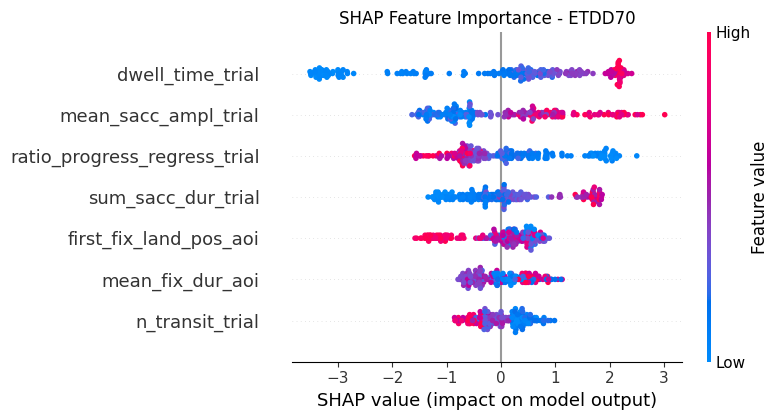


SHAP FEATURE IMPORTANCE


,Rank,Feature,Mean_Absolute_SHAP
0,1,dwell_time_trial,1.56701
1,2,mean_sacc_ampl_trial,0.99116
2,3,ratio_progress_regress_trial,0.80198
3,4,sum_sacc_dur_trial,0.69516
4,5,first_fix_land_pos_aoi,0.51411
5,6,mean_fix_dur_aoi,0.42268
6,7,n_transit_trial,0.35135



Saved as: ETDD70_SHAP_feature_importance.csv


In [ ]:
# ============================================
# STEP 9: SHAP EXPLAINABILITY
# ============================================

# Install SHAP if necessary
!pip -q install shap

import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from xgboost import XGBClassifier


print("Preparing SHAP explainability analysis...")


# --------------------------------------------
# Prepare data
# --------------------------------------------

X_shap = ml_df[ml_features].copy()

y_shap = ml_df["label"].map({
    "non-dyslexic": 0,
    "dyslexic": 1
})


# --------------------------------------------
# Train XGBoost for interpretation
# --------------------------------------------

shap_model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)

shap_model.fit(
    X_shap,
    y_shap
)


print("XGBoost model trained.")
print("Generating SHAP values...")


# --------------------------------------------
# Create SHAP explainer
# --------------------------------------------

explainer = shap.TreeExplainer(
    shap_model
)

shap_values = explainer.shap_values(
    X_shap
)


print("SHAP values generated.")


# --------------------------------------------
# SHAP summary plot
# --------------------------------------------

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X_shap,
    show=False
)

plt.title(
    "SHAP Feature Importance - ETDD70"
)

plt.tight_layout()
plt.show()


# --------------------------------------------
# Calculate mean absolute SHAP importance
# --------------------------------------------

mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "Feature": ml_features,
    "Mean_Absolute_SHAP": mean_abs_shap
})

shap_importance_df = (
    shap_importance_df
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

shap_importance_df["Rank"] = (
    np.arange(1, len(shap_importance_df) + 1)
)

shap_importance_df = shap_importance_df[
    ["Rank", "Feature", "Mean_Absolute_SHAP"]
]


print("\n============================================")
print("SHAP FEATURE IMPORTANCE")
print("============================================")

display(
    shap_importance_df.round(5)
)


# --------------------------------------------
# Save results
# --------------------------------------------

shap_importance_df.to_csv(
    "ETDD70_SHAP_feature_importance.csv",
    index=False
)

print(
    "\nSaved as: "
    "ETDD70_SHAP_feature_importance.csv"
)

In [ ]:
# ============================================
# STEP 10 — INTEGRATE FEATURE EVIDENCE
# ============================================

print("Integrating statistical, stability, and SHAP evidence...")

# Mean absolute effect size across all three tasks
effect_summary = (
    stats_df.groupby("feature")["abs_effect_size"]
    .mean()
    .reset_index()
    .rename(columns={"abs_effect_size": "Mean_Abs_Effect_Size"})
)

# Number of tasks where feature was statistically significant
significance_summary = (
    stats_df.groupby("feature")["significant"]
    .sum()
    .reset_index()
    .rename(columns={"significant": "Significant_Tasks"})
)

# SHAP importance
shap_summary = shap_importance_df[
    ["Feature", "Mean_Absolute_SHAP", "Rank"]
].copy()

shap_summary = shap_summary.rename(
    columns={"Feature": "feature"}
)

# Merge all evidence
feature_evidence = (
    effect_summary
    .merge(significance_summary, on="feature")
    .merge(shap_summary, on="feature")
)

# Keep only our 7 candidate features
feature_evidence = feature_evidence[
    feature_evidence["feature"].isin(selected_features)
].copy()

# Sort by SHAP importance
feature_evidence = feature_evidence.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

# Final evidence rank
feature_evidence["Evidence_Rank"] = range(
    1, len(feature_evidence) + 1
)

print("\n============================================")
print("FINAL FEATURE EVIDENCE TABLE")
print("============================================")

display(feature_evidence)

# Save results
feature_evidence.to_csv(
    "ETDD70_final_feature_evidence.csv",
    index=False
)

print("\nSaved as: ETDD70_final_feature_evidence.csv")

Integrating statistical, stability, and SHAP evidence...

FINAL FEATURE EVIDENCE TABLE


,feature,Mean_Abs_Effect_Size,Significant_Tasks,Mean_Absolute_SHAP,Rank,Evidence_Rank
0,dwell_time_trial,0.846531,3,1.567006,1,1
1,mean_sacc_ampl_trial,0.546667,3,0.991163,2,2
2,ratio_progress_regress_trial,0.522449,3,0.801976,3,3
3,sum_sacc_dur_trial,0.726259,3,0.695162,4,4
4,first_fix_land_pos_aoi,0.395374,3,0.514108,5,5
5,mean_fix_dur_aoi,0.701769,3,0.422676,6,6
6,n_transit_trial,0.632381,3,0.351352,7,7



Saved as: ETDD70_final_feature_evidence.csv


In [ ]:
# ============================================
# STEP 11 — TASK-WISE SHAP STABILITY
# ============================================

print("Starting task-wise SHAP analysis...")

task_shap_results = []

tasks = ml_df["task_name"].unique()

for task in tasks:

    print(f"\nProcessing task: {task}")

    # Select one task
    task_data = ml_df[ml_df["task_name"] == task].copy()

    X_task = task_data[selected_features]
    y_task = task_data["label"].map({
        "non-dyslexic": 0,
        "dyslexic": 1
    })

    # Train XGBoost for interpretation
    task_model = XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    )

    task_model.fit(X_task, y_task)

    # SHAP
    task_explainer = shap.TreeExplainer(task_model)
    task_shap_values = task_explainer.shap_values(X_task)

    # Mean absolute SHAP
    mean_abs_shap = np.abs(task_shap_values).mean(axis=0)

    for feature, importance in zip(
        selected_features,
        mean_abs_shap
    ):
        task_shap_results.append({
            "Task": task,
            "Feature": feature,
            "Mean_Absolute_SHAP": importance
        })


# Convert to dataframe
task_shap_df = pd.DataFrame(task_shap_results)

# Add rank within each task
task_shap_df["SHAP_Rank"] = (
    task_shap_df
    .groupby("Task")["Mean_Absolute_SHAP"]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

# Sort
task_shap_df = task_shap_df.sort_values(
    ["Task", "SHAP_Rank"]
).reset_index(drop=True)

print("\n============================================")
print("TASK-WISE SHAP FEATURE IMPORTANCE")
print("============================================")

display(task_shap_df)

# Save
task_shap_df.to_csv(
    "ETDD70_taskwise_SHAP_importance.csv",
    index=False
)

print("\nSaved as: ETDD70_taskwise_SHAP_importance.csv")

Starting task-wise SHAP analysis...

Processing task: Syllables

Processing task: Meaningful_Text

Processing task: Pseudo_Text

TASK-WISE SHAP FEATURE IMPORTANCE


,Task,Feature,Mean_Absolute_SHAP,SHAP_Rank
0,Meaningful_Text,dwell_time_trial,1.521008,1
1,Meaningful_Text,n_transit_trial,0.984066,2
2,Meaningful_Text,ratio_progress_regress_trial,0.602898,3
3,Meaningful_Text,sum_sacc_dur_trial,0.567557,4
4,Meaningful_Text,first_fix_land_pos_aoi,0.374122,5
5,Meaningful_Text,mean_fix_dur_aoi,0.255208,6
6,Meaningful_Text,mean_sacc_ampl_trial,0.112269,7
7,Pseudo_Text,dwell_time_trial,1.421586,1
8,Pseudo_Text,sum_sacc_dur_trial,1.149222,2
9,Pseudo_Text,mean_fix_dur_aoi,1.148867,3



Saved as: ETDD70_taskwise_SHAP_importance.csv


In [ ]:
# ============================================
# STEP 12 — SHAP RANK STABILITY
# ============================================

print("Calculating SHAP rank stability...")

rank_stability = (
    task_shap_df
    .groupby("Feature")
    .agg(
        Mean_SHAP=("Mean_Absolute_SHAP", "mean"),
        Mean_Rank=("SHAP_Rank", "mean"),
        Rank_SD=("SHAP_Rank", "std"),
        Best_Rank=("SHAP_Rank", "min"),
        Worst_Rank=("SHAP_Rank", "max")
    )
    .reset_index()
)

# Rank features by mean SHAP rank
rank_stability = rank_stability.sort_values(
    ["Mean_Rank", "Rank_SD"]
).reset_index(drop=True)

# Assign final stability rank
rank_stability["Stability_Rank"] = range(
    1, len(rank_stability) + 1
)

print("\n============================================")
print("SHAP RANK STABILITY")
print("============================================")

display(rank_stability)

# Save
rank_stability.to_csv(
    "ETDD70_SHAP_rank_stability.csv",
    index=False
)

print("\nSaved as: ETDD70_SHAP_rank_stability.csv")

Calculating SHAP rank stability...

SHAP RANK STABILITY


,Feature,Mean_SHAP,Mean_Rank,Rank_SD,Best_Rank,Worst_Rank,Stability_Rank
0,dwell_time_trial,1.620807,1.000000,0.000000,1,1,1
1,sum_sacc_dur_trial,0.827845,3.333333,1.154701,2,4,2
2,n_transit_trial,0.533818,4.333333,2.516611,2,7,3
3,mean_fix_dur_aoi,0.657453,4.666667,1.527525,3,6,4
4,first_fix_land_pos_aoi,0.587931,4.666667,2.516611,2,7,5
5,ratio_progress_regress_trial,0.431154,5.000000,1.732051,3,6,6
6,mean_sacc_ampl_trial,0.454064,5.000000,2.000000,3,7,7



Saved as: ETDD70_SHAP_rank_stability.csv


In [ ]:
# ============================================
# STEP 13 — FINAL CANDIDATE BIOMARKER TABLE
# CORRECTED VERSION
# ============================================

print("Creating final candidate biomarker evidence table...")

# Start from the statistical + overall SHAP evidence
final_biomarkers = feature_evidence.copy()

# Add SHAP rank-stability information
final_biomarkers = final_biomarkers.merge(
    rank_stability[
        [
            "Feature",
            "Mean_Rank",
            "Rank_SD",
            "Best_Rank",
            "Worst_Rank",
            "Stability_Rank"
        ]
    ],
    left_on="feature",
    right_on="Feature",
    how="left"
)

# Remove duplicate feature-name column
final_biomarkers = final_biomarkers.drop(
    columns=["Feature"]
)

# Create stability category
def classify_stability(row):

    if row["Mean_Rank"] == 1 and row["Rank_SD"] == 0:
        return "Highly Stable"

    elif row["Rank_SD"] <= 1.5:
        return "Relatively Stable"

    else:
        return "Task-Dependent"

final_biomarkers["SHAP_Stability"] = (
    final_biomarkers.apply(
        classify_stability,
        axis=1
    )
)

# Sort according to SHAP stability rank
final_biomarkers = final_biomarkers.sort_values(
    "Stability_Rank"
).reset_index(drop=True)

print("\n============================================")
print("FINAL CANDIDATE BIOMARKER EVIDENCE")
print("============================================")

display(final_biomarkers)

# Save final table
final_biomarkers.to_csv(
    "ETDD70_final_candidate_biomarkers.csv",
    index=False
)

print("\nSaved as: ETDD70_final_candidate_biomarkers.csv")

Creating final candidate biomarker evidence table...

FINAL CANDIDATE BIOMARKER EVIDENCE


,feature,Mean_Abs_Effect_Size,Significant_Tasks,Mean_Absolute_SHAP,Rank,Evidence_Rank,Mean_Rank,Rank_SD,Best_Rank,Worst_Rank,Stability_Rank,SHAP_Stability
0,dwell_time_trial,0.846531,3,1.567006,1,1,1.000000,0.000000,1,1,1,Highly Stable
1,sum_sacc_dur_trial,0.726259,3,0.695162,4,4,3.333333,1.154701,2,4,2,Relatively Stable
2,n_transit_trial,0.632381,3,0.351352,7,7,4.333333,2.516611,2,7,3,Task-Dependent
3,mean_fix_dur_aoi,0.701769,3,0.422676,6,6,4.666667,1.527525,3,6,4,Task-Dependent
4,first_fix_land_pos_aoi,0.395374,3,0.514108,5,5,4.666667,2.516611,2,7,5,Task-Dependent
5,ratio_progress_regress_trial,0.522449,3,0.801976,3,3,5.000000,1.732051,3,6,6,Task-Dependent
6,mean_sacc_ampl_trial,0.546667,3,0.991163,2,2,5.000000,2.000000,3,7,7,Task-Dependent



Saved as: ETDD70_final_candidate_biomarkers.csv


In [ ]:
# ============================================
# STEP 14 — LEAKAGE-RESISTANT FINAL ML VALIDATION
# ============================================

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("Starting leakage-resistant participant-level validation...")

# --------------------------------------------
# 1. Prepare data
# --------------------------------------------

# Use ALL original numerical features
all_features = [
    col for col in master_df.columns
    if col not in [
        "subject_id",
        "task_name",
        "label"
    ]
]

X_final = master_df[all_features].copy()

y_final = master_df["label"].map({
    "non-dyslexic": 0,
    "dyslexic": 1
})

groups_final = master_df["subject_id"]

print("Number of features:", len(all_features))
print("Number of observations:", len(X_final))
print("Unique participants:", groups_final.nunique())

# --------------------------------------------
# 2. Define models
# --------------------------------------------

models_final = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    )
}

# --------------------------------------------
# 3. Participant-level 5-fold CV
# --------------------------------------------

cv_final = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

final_results = []

for model_name, model in models_final.items():

    print(f"\nEvaluating: {model_name}")

    fold_metrics = []

    for fold, (train_idx, test_idx) in enumerate(
        cv_final.split(
            X_final,
            y_final,
            groups_final
        ),
        start=1
    ):

        X_train = X_final.iloc[train_idx]
        X_test = X_final.iloc[test_idx]

        y_train = y_final.iloc[train_idx]
        y_test = y_final.iloc[test_idx]

        # Train only on training participants
        model.fit(X_train, y_train)

        # Predictions
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        # Confusion matrix
        tn, fp, fn, tp = confusion_matrix(
            y_test,
            y_pred
        ).ravel()

        # Metrics
        accuracy = accuracy_score(
            y_test,
            y_pred
        )

        balanced_acc = balanced_accuracy_score(
            y_test,
            y_pred
        )

        precision = precision_score(
            y_test,
            y_pred,
            zero_division=0
        )

        sensitivity = recall_score(
            y_test,
            y_pred,
            zero_division=0
        )

        specificity = (
            tn / (tn + fp)
            if (tn + fp) > 0
            else 0
        )

        f1 = f1_score(
            y_test,
            y_pred,
            zero_division=0
        )

        auc = roc_auc_score(
            y_test,
            y_prob
        )

        fold_metrics.append({
            "Fold": fold,
            "Accuracy": accuracy,
            "Balanced_Accuracy": balanced_acc,
            "Precision": precision,
            "Sensitivity": sensitivity,
            "Specificity": specificity,
            "F1": f1,
            "ROC_AUC": auc
        })

    fold_df = pd.DataFrame(fold_metrics)

    final_results.append({
        "Model": model_name,
        "Accuracy_Mean": fold_df["Accuracy"].mean(),
        "Accuracy_SD": fold_df["Accuracy"].std(),
        "Balanced_Accuracy": fold_df["Balanced_Accuracy"].mean(),
        "Precision": fold_df["Precision"].mean(),
        "Sensitivity": fold_df["Sensitivity"].mean(),
        "Specificity": fold_df["Specificity"].mean(),
        "F1_Mean": fold_df["F1"].mean(),
        "F1_SD": fold_df["F1"].std(),
        "ROC_AUC_Mean": fold_df["ROC_AUC"].mean(),
        "ROC_AUC_SD": fold_df["ROC_AUC"].std()
    })

# --------------------------------------------
# 4. Final results table
# --------------------------------------------

final_ml_results = pd.DataFrame(
    final_results
).sort_values(
    "ROC_AUC_Mean",
    ascending=False
).reset_index(drop=True)

print("\n============================================")
print("LEAKAGE-RESISTANT FINAL ML RESULTS")
print("============================================")

display(final_ml_results)

# --------------------------------------------
# 5. Save results
# --------------------------------------------

final_ml_results.to_csv(
    "ETDD70_FINAL_LEAKAGE_RESISTANT_ML_RESULTS.csv",
    index=False
)

print(
    "\nSaved as: "
    "ETDD70_FINAL_LEAKAGE_RESISTANT_ML_RESULTS.csv"
)

Starting leakage-resistant participant-level validation...
Number of features: 29
Number of observations: 210
Unique participants: 70

Evaluating: Logistic Regression

Evaluating: Random Forest

Evaluating: XGBoost

LEAKAGE-RESISTANT FINAL ML RESULTS


,Model,Accuracy_Mean,Accuracy_SD,Balanced_Accuracy,Precision,Sensitivity,Specificity,F1_Mean,F1_SD,ROC_AUC_Mean,ROC_AUC_SD
0,Logistic Regression,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.0,0.0
1,Random Forest,0.961905,0.059761,0.966071,0.990909,0.941667,0.990476,0.962522,0.059956,1.0,0.0
2,XGBoost,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.0,0.0



Saved as: ETDD70_FINAL_LEAKAGE_RESISTANT_ML_RESULTS.csv


In [ ]:
# ============================================
# STEP 15 — AUDIT FEATURES FOR POSSIBLE LEAKAGE
# ============================================

print("Auditing features for possible class leakage...")

# Check all feature names
print("\nFEATURES USED:")
for i, feature in enumerate(all_features, start=1):
    print(f"{i:02d}. {feature}")

# --------------------------------------------
# Check correlation with class label
# --------------------------------------------

audit_results = []

for feature in all_features:

    dys = master_df.loc[
        master_df["label"] == "dyslexic",
        feature
    ].astype(float)

    non_dys = master_df.loc[
        master_df["label"] == "non-dyslexic",
        feature
    ].astype(float)

    audit_results.append({
        "Feature": feature,
        "Dyslexic_Mean": dys.mean(),
        "Non_Dyslexic_Mean": non_dys.mean(),
        "Dyslexic_SD": dys.std(),
        "Non_Dyslexic_SD": non_dys.std(),
        "Mean_Difference": abs(
            dys.mean() - non_dys.mean()
        )
    })

feature_audit = pd.DataFrame(audit_results)

feature_audit = feature_audit.sort_values(
    "Mean_Difference",
    ascending=False
).reset_index(drop=True)

print("\n============================================")
print("FEATURE AUDIT")
print("============================================")

display(feature_audit)

# Save
feature_audit.to_csv(
    "ETDD70_feature_leakage_audit.csv",
    index=False
)

print("\nSaved as: ETDD70_feature_leakage_audit.csv")

Auditing features for possible class leakage...

FEATURES USED:
01. task_number
02. class_id
03. n_fix_trial
04. sum_fix_dur_trial
05. dwell_time_trial
06. mean_fix_dur_trial
07. n_sacc_trial
08. sum_sacc_dur_trial
09. mean_sacc_dur_trial
10. mean_sacc_ampl_trial
11. ratio_progress_regress_trial
12. n_between_line_regress_trial
13. n_within_line_regress_trial
14. n_regress_trial
15. n_progress_trial
16. n_transit_trial
17. dwell_time_aoi
18. n_fix_aoi
19. sum_fix_dur_aoi
20. mean_fix_dur_aoi
21. skipped_aoi
22. n_fix_first_visit_aoi
23. first_fix_dur_aoi
24. first_fix_land_pos_aoi
25. dwell_time_first_visit_aoi
26. sum_fix_dur_first_visit_aoi
27. sum_fix_dur_after_first_visit_aoi
28. dwell_time_rereading_aoi
29. n_revisits_aoi

FEATURE AUDIT


,Feature,Dyslexic_Mean,Non_Dyslexic_Mean,Dyslexic_SD,Non_Dyslexic_SD,Mean_Difference
0,dwell_time_trial,180887.583371,94150.853952,100366.009287,38075.112708,86736.729419
1,sum_fix_dur_trial,170198.338819,87568.873581,95957.518027,36947.375863,82629.465238
2,sum_sacc_dur_trial,11779.503762,7345.876876,5670.174854,1936.966217,4433.626886
3,sum_fix_dur_aoi,6365.746382,3268.872316,3467.794585,1314.228570,3096.874066
4,dwell_time_aoi,3320.396901,1707.549542,1802.455934,674.250324,1612.847359
5,dwell_time_first_visit_aoi,2782.646659,1524.445682,1398.025657,584.128501,1258.200977
6,sum_fix_dur_first_visit_aoi,2660.419373,1455.410890,1345.775542,569.216110,1205.008483
7,dwell_time_rereading_aoi,537.750242,183.103860,483.611906,125.234724,354.646382
8,sum_fix_dur_after_first_visit_aoi,522.453817,179.025268,466.169014,121.823613,343.428550
9,mean_fix_dur_aoi,1271.594912,940.295775,381.717286,268.948776,331.299137



Saved as: ETDD70_feature_leakage_audit.csv


In [ ]:
# ============================================
# STEP 16 — CORRECTED LEAKAGE-FREE ML VALIDATION
# ============================================

print("Running corrected leakage-free validation...")

# --------------------------------------------
# 1. Remove target/metadata leakage
# --------------------------------------------

excluded_features = [
    "subject_id",
    "task_name",
    "label",
    "class_id",
    "task_number"
]

clean_features = [
    col for col in master_df.columns
    if col not in excluded_features
]

X_clean = master_df[clean_features].copy()

y_clean = master_df["label"].map({
    "non-dyslexic": 0,
    "dyslexic": 1
})

groups_clean = master_df["subject_id"]

print("Number of genuine eye-tracking features:", len(clean_features))
print("Number of observations:", len(X_clean))
print("Unique participants:", groups_clean.nunique())

# --------------------------------------------
# 2. Define models
# --------------------------------------------

models_clean = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    )
}

# --------------------------------------------
# 3. Participant-level CV
# --------------------------------------------

cv_clean = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

clean_results = []

for model_name, model in models_clean.items():

    print(f"\nEvaluating: {model_name}")

    fold_metrics = []

    for fold, (train_idx, test_idx) in enumerate(
        cv_clean.split(
            X_clean,
            y_clean,
            groups_clean
        ),
        start=1
    ):

        X_train = X_clean.iloc[train_idx]
        X_test = X_clean.iloc[test_idx]

        y_train = y_clean.iloc[train_idx]
        y_test = y_clean.iloc[test_idx]

        # Train ONLY on training participants
        model.fit(X_train, y_train)

        # Predictions
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        # Confusion matrix
        tn, fp, fn, tp = confusion_matrix(
            y_test,
            y_pred
        ).ravel()

        accuracy = accuracy_score(
            y_test,
            y_pred
        )

        balanced_acc = balanced_accuracy_score(
            y_test,
            y_pred
        )

        precision = precision_score(
            y_test,
            y_pred,
            zero_division=0
        )

        sensitivity = recall_score(
            y_test,
            y_pred,
            zero_division=0
        )

        specificity = (
            tn / (tn + fp)
            if (tn + fp) > 0
            else 0
        )

        f1 = f1_score(
            y_test,
            y_pred,
            zero_division=0
        )

        auc = roc_auc_score(
            y_test,
            y_prob
        )

        fold_metrics.append({
            "Fold": fold,
            "Accuracy": accuracy,
            "Balanced_Accuracy": balanced_acc,
            "Precision": precision,
            "Sensitivity": sensitivity,
            "Specificity": specificity,
            "F1": f1,
            "ROC_AUC": auc
        })

    fold_df = pd.DataFrame(fold_metrics)

    clean_results.append({
        "Model": model_name,
        "Accuracy_Mean": fold_df["Accuracy"].mean(),
        "Accuracy_SD": fold_df["Accuracy"].std(),
        "Balanced_Accuracy": fold_df["Balanced_Accuracy"].mean(),
        "Precision": fold_df["Precision"].mean(),
        "Sensitivity": fold_df["Sensitivity"].mean(),
        "Specificity": fold_df["Specificity"].mean(),
        "F1_Mean": fold_df["F1"].mean(),
        "F1_SD": fold_df["F1"].std(),
        "ROC_AUC_Mean": fold_df["ROC_AUC"].mean(),
        "ROC_AUC_SD": fold_df["ROC_AUC"].std()
    })

# --------------------------------------------
# 4. Final corrected results
# --------------------------------------------

corrected_ml_results = pd.DataFrame(
    clean_results
).sort_values(
    "ROC_AUC_Mean",
    ascending=False
).reset_index(drop=True)

print("\n============================================")
print("CORRECTED LEAKAGE-FREE ML RESULTS")
print("============================================")

display(corrected_ml_results)

# --------------------------------------------
# 5. Save
# --------------------------------------------

corrected_ml_results.to_csv(
    "ETDD70_CORRECTED_LEAKAGE_FREE_ML_RESULTS.csv",
    index=False
)

print(
    "\nSaved as: "
    "ETDD70_CORRECTED_LEAKAGE_FREE_ML_RESULTS.csv"
)

Running corrected leakage-free validation...
Number of genuine eye-tracking features: 27
Number of observations: 210
Unique participants: 70

Evaluating: Logistic Regression

Evaluating: Random Forest

Evaluating: XGBoost

CORRECTED LEAKAGE-FREE ML RESULTS


,Model,Accuracy_Mean,Accuracy_SD,Balanced_Accuracy,Precision,Sensitivity,Specificity,F1_Mean,F1_SD,ROC_AUC_Mean,ROC_AUC_SD
0,Logistic Regression,0.742857,0.084850,0.760979,0.791697,0.730952,0.791005,0.724349,0.117789,0.884754,0.078194
1,XGBoost,0.723810,0.099032,0.741138,0.743480,0.716667,0.765608,0.705881,0.131082,0.842848,0.105733
2,Random Forest,0.742857,0.084850,0.755886,0.750608,0.753571,0.758201,0.735983,0.100557,0.837468,0.103349



Saved as: ETDD70_CORRECTED_LEAKAGE_FREE_ML_RESULTS.csv


In [ ]:
# ============================================================
# STEP 17 — FINAL CROSS-TASK GENERALIZATION SUMMARY
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Running final cross-task evaluation...")

# ------------------------------------------------------------
# 1. Selected eye-tracking features
# ------------------------------------------------------------

features = [
    "dwell_time_trial",
    "sum_sacc_dur_trial",
    "mean_fix_dur_aoi",
    "n_transit_trial",
    "mean_sacc_ampl_trial",
    "ratio_progress_regress_trial",
    "first_fix_land_pos_aoi"
]

data = ml_df.copy()

X = data[features]

y = data["label"].map({
    "non-dyslexic": 0,
    "dyslexic": 1
})

# ------------------------------------------------------------
# 2. Cross-task experiments
# ------------------------------------------------------------

experiments = [
    {
        "train_tasks": ["Syllables", "Meaningful_Text"],
        "test_task": "Pseudo_Text"
    },
    {
        "train_tasks": ["Syllables", "Pseudo_Text"],
        "test_task": "Meaningful_Text"
    },
    {
        "train_tasks": ["Meaningful_Text", "Pseudo_Text"],
        "test_task": "Syllables"
    }
]

results = []

# ------------------------------------------------------------
# 3. Participant-level information
# ------------------------------------------------------------

unique_subjects = (
    data[["subject_id", "label"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

subject_y = unique_subjects["label"].map({
    "non-dyslexic": 0,
    "dyslexic": 1
})

subject_groups = unique_subjects["subject_id"]

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# 4. Run each cross-task experiment
# ------------------------------------------------------------

for exp in experiments:

    train_tasks = exp["train_tasks"]
    test_task = exp["test_task"]

    fold_metrics = []

    print("\n--------------------------------------------")
    print("Training tasks:", train_tasks)
    print("Unseen test task:", test_task)
    print("--------------------------------------------")

    for fold, (train_sub_idx, test_sub_idx) in enumerate(
        cv.split(
            unique_subjects,
            subject_y,
            groups=subject_groups
        ),
        start=1
    ):

        # Participants used for training/testing
        train_subjects = set(
            unique_subjects.iloc[train_sub_idx]["subject_id"]
        )

        test_subjects = set(
            unique_subjects.iloc[test_sub_idx]["subject_id"]
        )

        # ----------------------------------------------------
        # Training data:
        # Two tasks from training participants
        # ----------------------------------------------------

        train_mask = (
            data["subject_id"].isin(train_subjects)
            & data["task_name"].isin(train_tasks)
        )

        # ----------------------------------------------------
        # Testing data:
        # Unseen task from completely held-out participants
        # ----------------------------------------------------

        test_mask = (
            data["subject_id"].isin(test_subjects)
            & (data["task_name"] == test_task)
        )

        X_train = data.loc[train_mask, features]
        y_train = y.loc[train_mask]

        X_test = data.loc[test_mask, features]
        y_test = y.loc[test_mask]

        # ----------------------------------------------------
        # Logistic Regression
        # ----------------------------------------------------

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(
                max_iter=2000,
                random_state=42
            ))
        ])

        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        # ----------------------------------------------------
        # Confusion matrix values
        # ----------------------------------------------------

        tn = np.sum((y_test == 0) & (y_pred == 0))
        fp = np.sum((y_test == 0) & (y_pred == 1))
        fn = np.sum((y_test == 1) & (y_pred == 0))
        tp = np.sum((y_test == 1) & (y_pred == 1))

        # Sensitivity
        sensitivity = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else 0
        )

        # Specificity
        specificity = (
            tn / (tn + fp)
            if (tn + fp) > 0
            else 0
        )

        fold_metrics.append({
            "accuracy": accuracy_score(y_test, y_pred),
            "balanced_accuracy": balanced_accuracy_score(
                y_test, y_pred
            ),
            "precision": precision_score(
                y_test, y_pred, zero_division=0
            ),
            "sensitivity": sensitivity,
            "specificity": specificity,
            "f1": f1_score(
                y_test, y_pred, zero_division=0
            ),
            "roc_auc": roc_auc_score(
                y_test, y_prob
            )
        })

    # --------------------------------------------------------
    # 5. Average across 5 folds
    # --------------------------------------------------------

    fold_df = pd.DataFrame(fold_metrics)

    results.append({
        "Train_Tasks": " + ".join(train_tasks),
        "Unseen_Test_Task": test_task,

        "Accuracy_Mean": fold_df["accuracy"].mean(),
        "Accuracy_SD": fold_df["accuracy"].std(),

        "Balanced_Accuracy": fold_df[
            "balanced_accuracy"
        ].mean(),

        "Precision": fold_df["precision"].mean(),

        "Sensitivity": fold_df["sensitivity"].mean(),

        "Specificity": fold_df["specificity"].mean(),

        "F1_Mean": fold_df["f1"].mean(),
        "F1_SD": fold_df["f1"].std(),

        "ROC_AUC_Mean": fold_df["roc_auc"].mean(),
        "ROC_AUC_SD": fold_df["roc_auc"].std()
    })

# ------------------------------------------------------------
# 6. Final table
# ------------------------------------------------------------

final_cross_task_results = pd.DataFrame(results)

print("\n")
print("=" * 75)
print("FINAL CROSS-TASK GENERALIZATION RESULTS")
print("=" * 75)

display(
    final_cross_task_results.round(4)
)

# ------------------------------------------------------------
# 7. Save
# ------------------------------------------------------------

output_file = "ETDD70_FINAL_CROSS_TASK_RESULTS.csv"

final_cross_task_results.to_csv(
    output_file,
    index=False
)

print("\nSaved as:", output_file)

Running final cross-task evaluation...

--------------------------------------------
Training tasks: ['Syllables', 'Meaningful_Text']
Unseen test task: Pseudo_Text
--------------------------------------------

--------------------------------------------
Training tasks: ['Syllables', 'Pseudo_Text']
Unseen test task: Meaningful_Text
--------------------------------------------

--------------------------------------------
Training tasks: ['Meaningful_Text', 'Pseudo_Text']
Unseen test task: Syllables
--------------------------------------------


FINAL CROSS-TASK GENERALIZATION RESULTS


,Train_Tasks,Unseen_Test_Task,Accuracy_Mean,Accuracy_SD,Balanced_Accuracy,Precision,Sensitivity,Specificity,F1_Mean,F1_SD,ROC_AUC_Mean,ROC_AUC_SD
0,Syllables + Meaningful_Text,Pseudo_Text,0.5429,0.1298,0.5476,0.5267,1.0000,0.0952,0.6841,0.1009,0.9014,0.0807
1,Syllables + Pseudo_Text,Meaningful_Text,0.6286,0.1629,0.6421,0.8000,0.2843,1.0000,0.4000,0.2937,0.9016,0.0903
2,Meaningful_Text + Pseudo_Text,Syllables,0.6857,0.1644,0.7032,0.9429,0.4636,0.9429,0.5651,0.2613,0.8547,0.1151



Saved as: ETDD70_FINAL_CROSS_TASK_RESULTS.csv


In [ ]:
# ============================================================
# STEP 18 — FINAL CANDIDATE BIOMARKER EVIDENCE TABLE
# FINAL CORRECTED VERSION
# ============================================================

import pandas as pd
import numpy as np

print("Creating final candidate biomarker evidence table...")

# ------------------------------------------------------------
# 1. Candidate features
# ------------------------------------------------------------

candidate_features = [
    "dwell_time_trial",
    "sum_sacc_dur_trial",
    "mean_fix_dur_aoi",
    "n_transit_trial",
    "mean_sacc_ampl_trial",
    "ratio_progress_regress_trial",
    "first_fix_land_pos_aoi"
]

# ------------------------------------------------------------
# 2. Statistical evidence
# ------------------------------------------------------------

stats = stats_df.copy()

stats_selected = stats[
    stats["feature"].isin(candidate_features)
].copy()

stats_summary = (
    stats_selected
    .groupby("feature")
    .agg(
        Mean_Absolute_Effect_Size=("abs_effect_size", "mean"),
        Significant_Tasks=("significant", "sum"),
        Mean_Adjusted_P=("adjusted_p", "mean")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 3. SHAP global importance
# ------------------------------------------------------------

shap_global = pd.read_csv(
    "ETDD70_SHAP_feature_importance.csv"
)

shap_selected = shap_global[
    shap_global["Feature"].isin(candidate_features)
].copy()

shap_selected = shap_selected[
    ["Feature", "Mean_Absolute_SHAP"]
].rename(
    columns={
        "Feature": "feature",
        "Mean_Absolute_SHAP": "Mean_SHAP_Importance"
    }
)

shap_selected["Overall_SHAP_Rank"] = (
    shap_selected["Mean_SHAP_Importance"]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

# ------------------------------------------------------------
# 4. SHAP rank stability
# ------------------------------------------------------------

shap_stability = pd.read_csv(
    "ETDD70_SHAP_rank_stability.csv"
)

stability_selected = shap_stability[
    shap_stability["Feature"].isin(candidate_features)
].copy()

stability_selected = stability_selected.rename(
    columns={
        "Feature": "feature",
        "Mean_Rank": "Mean_Rank",
        "Rank_SD": "Rank_SD",
        "Best_Rank": "Best_Rank",
        "Worst_Rank": "Worst_Rank",
        "Stability_Rank": "Stability_Rank"
    }
)

stability_selected = stability_selected[
    [
        "feature",
        "Mean_Rank",
        "Rank_SD",
        "Best_Rank",
        "Worst_Rank",
        "Stability_Rank"
    ]
]

# ------------------------------------------------------------
# 5. Merge all evidence
# ------------------------------------------------------------

final_biomarkers = (
    stats_summary
    .merge(
        shap_selected,
        on="feature",
        how="left"
    )
    .merge(
        stability_selected,
        on="feature",
        how="left"
    )
)

# ------------------------------------------------------------
# 6. Stability interpretation
# ------------------------------------------------------------

def classify_stability(rank_sd):

    if rank_sd == 0:
        return "Highly Stable"

    elif rank_sd <= 1.5:
        return "Relatively Stable"

    else:
        return "Task-Dependent"


final_biomarkers["SHAP_Stability"] = (
    final_biomarkers["Rank_SD"]
    .apply(classify_stability)
)

# ------------------------------------------------------------
# 7. Sort by SHAP importance
# ------------------------------------------------------------

final_biomarkers = (
    final_biomarkers
    .sort_values(
        "Mean_SHAP_Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 8. Display final table
# ------------------------------------------------------------

print("\n")
print("=" * 100)
print("FINAL CANDIDATE BIOMARKER EVIDENCE")
print("=" * 100)

display(
    final_biomarkers.round(4)
)

# ------------------------------------------------------------
# 9. Save final table
# ------------------------------------------------------------

output_file = (
    "ETDD70_FINAL_CANDIDATE_BIOMARKER_EVIDENCE.csv"
)

final_biomarkers.to_csv(
    output_file,
    index=False
)

print("\nSaved as:", output_file)

Creating final candidate biomarker evidence table...


FINAL CANDIDATE BIOMARKER EVIDENCE


,feature,Mean_Absolute_Effect_Size,Significant_Tasks,Mean_Adjusted_P,Mean_SHAP_Importance,Overall_SHAP_Rank,Mean_Rank,Rank_SD,Best_Rank,Worst_Rank,Stability_Rank,SHAP_Stability
0,dwell_time_trial,0.8465,3,0.0000,1.5670,1,1.0000,0.0000,1,1,1,Highly Stable
1,mean_sacc_ampl_trial,0.5467,3,0.0001,0.9912,2,5.0000,2.0000,3,7,7,Task-Dependent
2,ratio_progress_regress_trial,0.5224,3,0.0005,0.8020,3,5.0000,1.7321,3,6,6,Task-Dependent
3,sum_sacc_dur_trial,0.7263,3,0.0000,0.6952,4,3.3333,1.1547,2,4,2,Relatively Stable
4,first_fix_land_pos_aoi,0.3954,3,0.0133,0.5141,5,4.6667,2.5166,2,7,5,Task-Dependent
5,mean_fix_dur_aoi,0.7018,3,0.0000,0.4227,6,4.6667,1.5275,3,6,4,Task-Dependent
6,n_transit_trial,0.6324,3,0.0001,0.3514,7,4.3333,2.5166,2,7,3,Task-Dependent



Saved as: ETDD70_FINAL_CANDIDATE_BIOMARKER_EVIDENCE.csv


Models available:
['Logistic Regression', 'XGBoost', 'Random Forest']


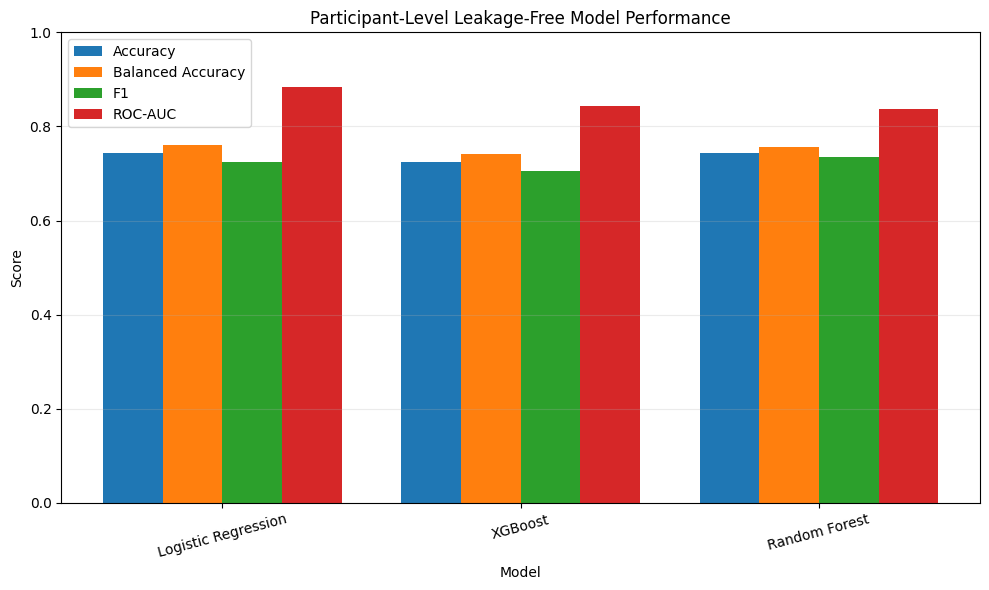


Saved as: ETDD70_FINAL_LEAKAGE_FREE_MODEL_COMPARISON.png


In [ ]:
# ============================================================
# STEP 19A — FINAL LEAKAGE-FREE ML MODEL COMPARISON FIGURE
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. Load corrected ML results
# ------------------------------------------------------------

ml_results = pd.read_csv(
    "ETDD70_CORRECTED_LEAKAGE_FREE_ML_RESULTS.csv"
)

print("Models available:")
print(ml_results["Model"].tolist())

# ------------------------------------------------------------
# 2. Prepare metrics
# ------------------------------------------------------------

models = ml_results["Model"].tolist()

accuracy = ml_results["Accuracy_Mean"].values
balanced_accuracy = ml_results["Balanced_Accuracy"].values
f1 = ml_results["F1_Mean"].values
roc_auc = ml_results["ROC_AUC_Mean"].values

x = np.arange(len(models))
width = 0.20

# ------------------------------------------------------------
# 3. Create figure
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    x - 1.5 * width,
    accuracy,
    width,
    label="Accuracy"
)

plt.bar(
    x - 0.5 * width,
    balanced_accuracy,
    width,
    label="Balanced Accuracy"
)

plt.bar(
    x + 0.5 * width,
    f1,
    width,
    label="F1"
)

plt.bar(
    x + 1.5 * width,
    roc_auc,
    width,
    label="ROC-AUC"
)

# ------------------------------------------------------------
# 4. Formatting
# ------------------------------------------------------------

plt.xticks(
    x,
    models,
    rotation=15
)

plt.ylabel("Score")

plt.xlabel("Model")

plt.title(
    "Participant-Level Leakage-Free Model Performance"
)

plt.ylim(0, 1.0)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

# ------------------------------------------------------------
# 5. Save figure
# ------------------------------------------------------------

figure_file = (
    "ETDD70_FINAL_LEAKAGE_FREE_MODEL_COMPARISON.png"
)

plt.savefig(
    figure_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved as:", figure_file)

Cross-task experiments:


,Train_Tasks,Unseen_Test_Task,Accuracy_Mean,Accuracy_SD,Balanced_Accuracy,Precision,Sensitivity,Specificity,F1_Mean,F1_SD,ROC_AUC_Mean,ROC_AUC_SD
0,Syllables + Meaningful_Text,Pseudo_Text,0.542857,0.129756,0.547619,0.526740,1.000000,0.095238,0.684051,0.100932,0.901446,0.080746
1,Syllables + Pseudo_Text,Meaningful_Text,0.628571,0.162882,0.642143,0.800000,0.284286,1.000000,0.400000,0.293684,0.901616,0.090319
2,Meaningful_Text + Pseudo_Text,Syllables,0.685714,0.164441,0.703214,0.942857,0.463571,0.942857,0.565079,0.261312,0.854654,0.115111


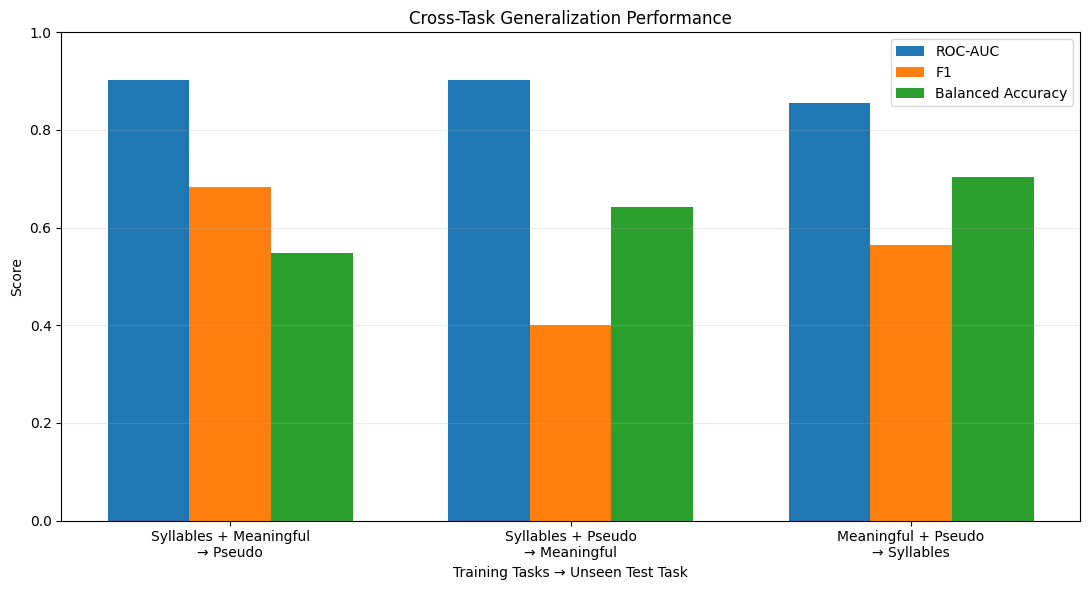


Saved as: ETDD70_FINAL_CROSS_TASK_GENERALIZATION.png


In [ ]:
# ============================================================
# STEP 19B — FINAL CROSS-TASK GENERALIZATION FIGURE
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. Load final cross-task results
# ------------------------------------------------------------

cross_task = pd.read_csv(
    "ETDD70_FINAL_CROSS_TASK_RESULTS.csv"
)

print("Cross-task experiments:")
display(cross_task)

# ------------------------------------------------------------
# 2. Short labels for the figure
# ------------------------------------------------------------

labels = [
    "Syllables + Meaningful\n→ Pseudo",
    "Syllables + Pseudo\n→ Meaningful",
    "Meaningful + Pseudo\n→ Syllables"
]

x = np.arange(len(labels))
width = 0.24

# ------------------------------------------------------------
# 3. Extract metrics
# ------------------------------------------------------------

roc_auc = cross_task["ROC_AUC_Mean"].values
f1 = cross_task["F1_Mean"].values
balanced_accuracy = cross_task["Balanced_Accuracy"].values

# ------------------------------------------------------------
# 4. Create figure
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

plt.bar(
    x - width,
    roc_auc,
    width,
    label="ROC-AUC"
)

plt.bar(
    x,
    f1,
    width,
    label="F1"
)

plt.bar(
    x + width,
    balanced_accuracy,
    width,
    label="Balanced Accuracy"
)

# ------------------------------------------------------------
# 5. Formatting
# ------------------------------------------------------------

plt.xticks(
    x,
    labels
)

plt.ylabel("Score")

plt.xlabel(
    "Training Tasks → Unseen Test Task"
)

plt.title(
    "Cross-Task Generalization Performance"
)

plt.ylim(0, 1.0)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

# ------------------------------------------------------------
# 6. Save
# ------------------------------------------------------------

figure_file = (
    "ETDD70_FINAL_CROSS_TASK_GENERALIZATION.png"
)

plt.savefig(
    figure_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved as:", figure_file)

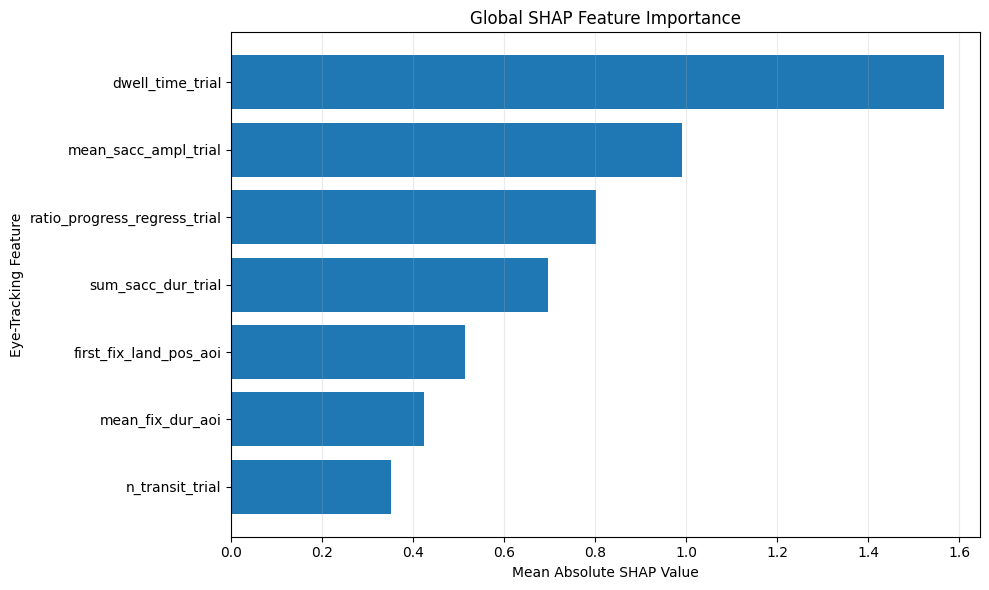


Saved as: ETDD70_FINAL_SHAP_FEATURE_IMPORTANCE.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load SHAP importance results
shap_df = pd.read_csv("ETDD70_SHAP_feature_importance.csv")

# Sort from lowest to highest for horizontal bar chart
shap_plot = shap_df.sort_values("Mean_Absolute_SHAP", ascending=True)

plt.figure(figsize=(10, 6))

plt.barh(
    shap_plot["Feature"],
    shap_plot["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Eye-Tracking Feature")
plt.title("Global SHAP Feature Importance")

plt.grid(axis="x", alpha=0.25)
plt.tight_layout()

figure_file = "ETDD70_FINAL_SHAP_FEATURE_IMPORTANCE.png"

plt.savefig(
    figure_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved as:", figure_file)

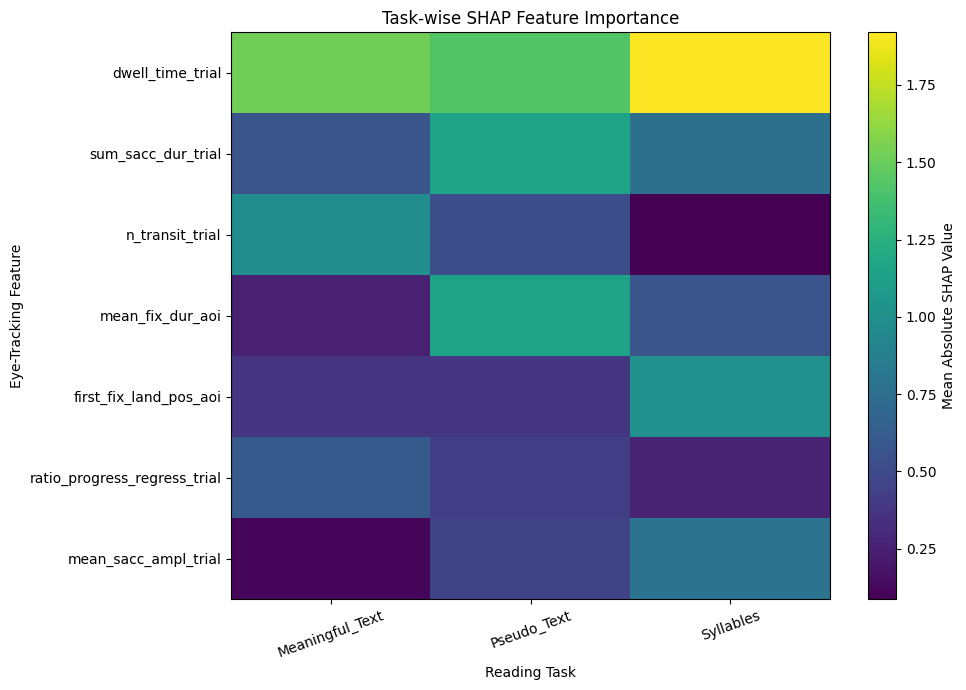


Saved as: ETDD70_FINAL_TASKWISE_SHAP_STABILITY.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load task-wise SHAP results
task_shap = pd.read_csv("ETDD70_taskwise_SHAP_importance.csv")

# Create pivot table
shap_pivot = task_shap.pivot(
    index="Feature",
    columns="Task",
    values="Mean_Absolute_SHAP"
)

# Keep the overall feature order
feature_order = [
    "dwell_time_trial",
    "sum_sacc_dur_trial",
    "n_transit_trial",
    "mean_fix_dur_aoi",
    "first_fix_land_pos_aoi",
    "ratio_progress_regress_trial",
    "mean_sacc_ampl_trial"
]

shap_pivot = shap_pivot.reindex(feature_order)

# Plot
plt.figure(figsize=(10, 7))

plt.imshow(
    shap_pivot.values,
    aspect="auto"
)

plt.xticks(
    range(len(shap_pivot.columns)),
    shap_pivot.columns,
    rotation=20
)

plt.yticks(
    range(len(shap_pivot.index)),
    shap_pivot.index
)

plt.xlabel("Reading Task")
plt.ylabel("Eye-Tracking Feature")
plt.title("Task-wise SHAP Feature Importance")

plt.colorbar(
    label="Mean Absolute SHAP Value"
)

plt.tight_layout()

figure_file = "ETDD70_FINAL_TASKWISE_SHAP_STABILITY.png"

plt.savefig(
    figure_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved as:", figure_file)

In [ ]:
import pandas as pd

results_summary = pd.DataFrame({
    "Research Question": [
        "RQ1: Which eye-tracking features best distinguish dyslexic and non-dyslexic participants?",
        "RQ2: Are important features consistent across reading tasks?",
        "RQ3: Can models generalize to an unseen reading task?",
        "RQ4: Which features contribute most to individual predictions?"
    ],

    "Key Finding": [
        "Seven candidate features showed significant class differences across all three tasks.",
        "24 of 27 examined features were statistically stable across all three tasks; the selected candidate features remained significant across tasks.",
        "Cross-task ROC-AUC ranged from 0.855 to 0.902, demonstrating transferable discriminative ranking ability.",
        "SHAP identified dwell_time_trial as the strongest overall contributor, followed by saccade and reading-progression features."
    ],

    "Main Evidence": [
        "Mann–Whitney U tests + effect sizes + FDR correction",
        "Cross-task significance + effect-size stability + task-wise SHAP",
        "Participant-level unseen-task evaluation",
        "Global and task-wise SHAP analysis"
    ]
})

display(results_summary)

results_summary.to_csv(
    "ETDD70_FINAL_RESULTS_SUMMARY.csv",
    index=False
)

print("\nSaved as: ETDD70_FINAL_RESULTS_SUMMARY.csv")

,Research Question,Key Finding,Main Evidence
0,RQ1: Which eye-tracking features best distingu...,Seven candidate features showed significant cl...,Mann–Whitney U tests + effect sizes + FDR corr...
1,RQ2: Are important features consistent across ...,24 of 27 examined features were statistically ...,Cross-task significance + effect-size stabilit...
2,RQ3: Can models generalize to an unseen readin...,"Cross-task ROC-AUC ranged from 0.855 to 0.902,...",Participant-level unseen-task evaluation
3,RQ4: Which features contribute most to individ...,SHAP identified dwell_time_trial as the strong...,Global and task-wise SHAP analysis



Saved as: ETDD70_FINAL_RESULTS_SUMMARY.csv


In [ ]:
print("=" * 70)
print("ETDD70 FINAL METHODOLOGY AUDIT")
print("=" * 70)

print("\n1. DATASET")
print("Participants:", master_df["subject_id"].nunique())
print("Participant-task observations:", len(master_df))
print("Tasks:", master_df["task_name"].unique().tolist())
print("Labels:", master_df["label"].value_counts().to_dict())

print("\n2. PARTICIPANT-LEVEL INTEGRITY")
rows_per_subject = master_df.groupby("subject_id").size()
print("Rows per participant:")
print(rows_per_subject.value_counts().sort_index())

print("\n3. SELECTED FEATURES")
print("Number of candidate features:", len(selected_features))
print("Selected features:")
for i, feature in enumerate(selected_features, 1):
    print(f"{i}. {feature}")

print("\n4. LEAKAGE CHECK")
leakage_columns = [
    "subject_id",
    "task_name",
    "label",
    "class_id",
    "task_number"
]

print("Excluded metadata/target columns:")
for col in leakage_columns:
    print("-", col)

print("\n5. FINAL ML FEATURES")
ml_features = [
    c for c in master_df.columns
    if c not in leakage_columns
]

print("Number of genuine eye-tracking features:", len(ml_features))

print("\n6. CROSS-TASK DESIGN")
print("Training on two tasks → testing on one unseen task")
print("Participant groups preserved during cross-validation")

print("\n7. SHAP")
print("SHAP used for interpretation, not performance estimation.")
print("Overall SHAP top feature: dwell_time_trial")

print("\n8. FINAL FIGURES")
figure_files = [
    "ETDD70_FINAL_LEAKAGE_FREE_MODEL_COMPARISON.png",
    "ETDD70_FINAL_CROSS_TASK_GENERALIZATION.png",
    "ETDD70_FINAL_SHAP_FEATURE_IMPORTANCE.png",
    "ETDD70_FINAL_TASKWISE_SHAP_STABILITY.png"
]

import os

for f in figure_files:
    print(f, "→", "FOUND" if os.path.exists(f) else "MISSING")

print("\n" + "=" * 70)
print("AUDIT COMPLETED")
print("=" * 70)

ETDD70 FINAL METHODOLOGY AUDIT

1. DATASET
Participants: 70
Participant-task observations: 210
Tasks: ['Syllables', 'Meaningful_Text', 'Pseudo_Text']
Labels: {'non-dyslexic': 105, 'dyslexic': 105}

2. PARTICIPANT-LEVEL INTEGRITY
Rows per participant:
3    70
Name: count, dtype: int64

3. SELECTED FEATURES
Number of candidate features: 7
Selected features:
1. dwell_time_trial
2. sum_sacc_dur_trial
3. mean_fix_dur_aoi
4. n_transit_trial
5. mean_sacc_ampl_trial
6. ratio_progress_regress_trial
7. first_fix_land_pos_aoi

4. LEAKAGE CHECK
Excluded metadata/target columns:
- subject_id
- task_name
- label
- class_id
- task_number

5. FINAL ML FEATURES
Number of genuine eye-tracking features: 27

6. CROSS-TASK DESIGN
Training on two tasks → testing on one unseen task
Participant groups preserved during cross-validation

7. SHAP
SHAP used for interpretation, not performance estimation.
Overall SHAP top feature: dwell_time_trial

8. FINAL FIGURES
ETDD70_FINAL_LEAKAGE_FREE_MODEL_COMPARISON.png → 